# Lab 4b — RNN, LSTM et GRU sur des données de capteurs (AI4I 2020)

**ENSIM · 5A ASTRE · De l'IA au LLM agentique · Séance 4**
*Bassem Ben Hamed & Ali Khalfallah*

Ce lab se fait **en autonomie, après la séance 4**. Il est entièrement consacré au jeu **AI4I 2020**, le fil rouge A de la maintenance prédictive, déjà vu aux labs 1 et 3. Ces deux labs traitaient chaque cycle de production isolément ; celui-ci exploite l'**ordre** des cycles, avec des réseaux récurrents. Une question guide tout le lab : **quand la mémoire d'un réseau récurrent sert-elle vraiment ?**

## Objectifs

À la fin du lab, vous savez :

1. situer le jeu AI4I 2020 : la maintenance prédictive, ce que simule le jeu et à quoi il sert ;
2. expliquer chaque **variable** : son sens physique, son unité, la façon dont elle est générée, et les **modes de panne** qu'elle provoque ;
3. mener une **analyse exploratoire** (*exploratory data analysis*, EDA) : déséquilibre des classes, distributions, corrélations, structure temporelle ;
4. transformer un tableau en **séquences** (fenêtres glissantes) et découper les données **sans fuite d'information** ;
5. implémenter un **RNN**, un **LSTM** et un **GRU** en PyTorch, et **compter leurs paramètres** par la formule et par PyTorch ;
6. **évaluer** un détecteur de pannes rares : précision, rappel, F1, précision moyenne (AP), seuil choisi sur la validation ;
7. **interpréter** : longueur de fenêtre, saillance temporelle, rappel par mode de panne, importance des variables, et ce que calcule la cellule d'un LSTM ;
8. estimer le coût de ces modèles sur un **STM32F446**.

## Prérequis et environnement

- Séances 3 et 4 ; lab 3 (MLP sur AI4I) ; notions de PyTorch.
- **Google Colab gratuit, un CPU suffit.** Les réseaux du lab ont quelques milliers de paramètres. À cette taille, le temps passe à lancer les calculs, pas à les faire : sur un Mac M4 Pro, le GPU (MPS) s'est montré de 2 à 28 fois plus lent que le CPU. Le lab tourne donc sur CPU, comme les labs 1 à 3. Durée d'exécution : environ 5 minutes (306 s) sur un Mac M4 Pro ; non mesurée sur Colab.

## Plan

| Section | Contenu |
|---|---|
| 1 | Le contexte : la maintenance prédictive et le jeu AI4I 2020 |
| 2 | Charger les données |
| 3 | Les variables, une par une |
| 4 | Analyse exploratoire : pannes, distributions, corrélations, règles, structure temporelle, découpage |
| 5 | Des cycles aux séquences : les fenêtres glissantes |
| 6 | RNN, LSTM, GRU : formules, modèles et paramètres |
| 7 | Détecter les pannes : entraînement, évaluation, interprétation |
| 8 | Sans capteur d'usure : un réseau récurrent comme capteur virtuel |
| 9 | Et sur cible embarquée ? |
| 10 | Exercices de validation, vérifiés automatiquement, puis corrigé |

> **Données** : *AI4I 2020 Predictive Maintenance Dataset* (Matzka, 2020), UCI Machine Learning Repository (id 601), licence CC BY 4.0. Repli si le site UCI est indisponible : le paquet `ucimlrepo`.

## Installation et imports

Sur Colab, `numpy`, `pandas`, `matplotlib`, `scikit-learn` et `torch` sont déjà installés. Rien n'est écrit à côté du notebook : les fichiers temporaires vont dans un dossier créé par `tempfile`.

In [1]:
import copy, math, os, tempfile, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, f1_score, precision_score, recall_score,
                             precision_recall_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
T0 = time.time()
DOSSIER = tempfile.mkdtemp(prefix="lab4b_")      # fichiers temporaires : rien n'est écrit à côté du notebook
print("torch", torch.__version__, "| calcul sur CPU,", torch.get_num_threads(), "fils")

def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-z))

def nb_params(modele):
    return sum(p.numel() for p in modele.parameters())

FACTEUR = {"rnn": 1, "gru": 3, "lstm": 4}          # nombre de blocs (portes et candidat) par cellule
CLASSES = {"rnn": nn.RNN, "gru": nn.GRU, "lstm": nn.LSTM}
FREQ, FLASH, SRAM = 180e6, 512 * 1024, 128 * 1024  # STM32F446 : 180 MHz, 512 Ko de Flash, 128 Ko de SRAM

torch 2.10.0 | calcul sur CPU, 8 fils


## 1. Le contexte : la maintenance prédictive et le jeu AI4I 2020

### Trois façons d'entretenir une machine

| Stratégie | Quand intervient-on ? | Limite |
|---|---|---|
| **Corrective** | après la panne | arrêt imprévu, pièce rebutée, production perdue |
| **Préventive** | à intervalle fixe : par exemple, on change l'outil toutes les $N$ pièces | on jette des outils encore bons, et une panne peut survenir avant l'échéance |
| **Prédictive** | quand un modèle, nourri par les capteurs, annonce une panne probable | il faut des données et un modèle fiables |

La maintenance prédictive est l'un des premiers usages industriels de l'IA **embarquée** : le modèle tourne au plus près de la machine, dans un capteur intelligent, un automate ou un microcontrôleur (section 9).

### Pourquoi un jeu synthétique ?

Les données réelles de maintenance sont difficiles à obtenir : les pannes sont rares, et un industriel publie rarement des données qui révèlent ses procédés et ses défauts. S. Matzka a donc construit **AI4I 2020**, un jeu **synthétique** qui, selon son auteur, reflète au mieux la maintenance prédictive rencontrée dans l'industrie. Il l'a publié avec l'article *Explainable Artificial Intelligence for Predictive Maintenance Applications*, à la conférence AI4I 2020 (*Artificial Intelligence for Industries*), d'où son nom.

### Ce que représente une ligne

Une ligne est un **cycle de production** : un produit usiné par un outil en rotation. Pour chacun des 10 000 cycles, rangés dans l'ordre de production, on connaît :

- la **qualité** du produit (L, M ou H) ;
- deux **températures** : celle de l'air ambiant et celle du procédé ;
- la **vitesse de rotation** et le **couple** de l'outil ;
- l'**usure** de l'outil ;
- l'**issue** du cycle : panne ou non et, en cas de panne, son ou ses **modes**, c'est-à-dire sa cause.

### À quoi sert ce jeu ?

Matzka l'a construit pour évaluer des méthodes d'**IA explicable** : les pannes y sont produites par des **règles connues** (section 3.6). On peut donc vérifier si un modèle a appris les vraies causes, ou des coïncidences. Deux tâches sont classiques :

1. une **classification binaire** : le cycle se termine-t-il par une panne ? C'est la tâche des labs 1 et 3, et de la section 7 ;
2. une **classification multi-classe** : quel est le mode de la panne ?

Ce lab ajoute une troisième tâche, que permet l'ordre des cycles : **estimer l'usure de l'outil sans la mesurer** (section 8).

### Ce que l'on sait déjà (labs 1 et 3)

Au lab 1, une forêt aléatoire détecte les pannes avec un F1 de 0,83 ; au lab 3, un MLP fait moins bien (F1 de 0,67). Les deux labs découpent les données **au hasard, ligne par ligne**, et ignorent donc l'ordre des cycles. La question de ce lab : cet ordre, lu par un réseau récurrent, apporte-t-il quelque chose ?

## 2. Charger les données

On lit l'archive du site UCI. **Repli** : le paquet `ucimlrepo`, installé à la demande. Les deux sources n'ont pas les mêmes en-têtes : l'archive écrit les unités (`Torque [Nm]`) et la colonne `UDI` ; `ucimlrepo` retire les unités et écrit `UID`. On retire donc les unités, puis on renomme. Les noms courts sont ceux des labs 1 et 3.

In [2]:
URL_AI4I = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"
try:
    brut = pd.read_csv(URL_AI4I, compression="zip")
    source = "archive du site UCI"
except Exception as e:  # repli si le site UCI est indisponible
    print("Téléchargement direct impossible :", type(e).__name__, "-> repli sur ucimlrepo")
    try:
        from ucimlrepo import fetch_ucirepo
    except ImportError:
        %pip install -q ucimlrepo
        from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=601)
    brut = pd.concat([ds.data.ids, ds.data.features, ds.data.targets], axis=1)
    source = "ucimlrepo (repli)"

brut.columns = [c.replace("﻿", "").split(" [")[0].strip() for c in brut.columns]
df = brut.rename(columns={"UID": "UDI", "Product ID": "produit", "Air temperature": "T_air_K",
                          "Process temperature": "T_process_K", "Rotational speed": "vitesse_rpm",
                          "Torque": "couple_Nm", "Tool wear": "usure_outil_min", "Machine failure": "panne"})
df = df.sort_values("UDI").reset_index(drop=True)          # l'ordre des UDI est l'ordre de production
print(f"source : {source} ; {df.shape[0]} lignes, {df.shape[1]} colonnes")
df.head(8)

source : archive du site UCI ; 10000 lignes, 14 colonnes


,UDI,produit,Type,T_air_K,T_process_K,vitesse_rpm,couple_Nm,usure_outil_min,panne,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,0,0,0,0,0
6,7,L47186,L,298.1,308.6,1558,42.4,14,0,0,0,0,0,0
7,8,L47187,L,298.1,308.6,1527,40.2,16,0,0,0,0,0,0


## 3. Les variables, une par une

Le fichier compte 14 colonnes : 2 identifiants, 1 variable catégorielle (le type), 5 mesures et 6 étiquettes. On y ajoute 3 **variables métier**, calculées à partir des mesures. Les plages indiquées sont celles des données ; les noms courts sont ceux des labs 1 et 3.

### 3.1 Les identifiants : `UDI` et `Product ID`

- `UDI` (*unique identifier*) numérote les cycles de 1 à 10 000. Les lignes sont dans l'ordre de production : `UDI` est **l'axe du temps** du lab. Ce n'est pas une entrée : un numéro de ligne ne cause pas de panne.
- `Product ID` (renommé `produit`) : la lettre du type suivie d'un numéro de série, par exemple `M14860`. Il est unique pour chaque produit et redondant avec le type : on l'écarte.

### 3.2 Le produit : `Type`

- La qualité du produit : **L** (*low*, basse), **M** (*medium*, moyenne) ou **H** (*high*, haute). Les données contiennent 60 % de L, 30 % de M et 10 % de H. La description officielle annonce 50 %, 30 % et 20 % : faites confiance aux données, et vérifiez toujours une documentation avant de vous appuyer dessus.
- Le type joue deux rôles dans le générateur :
  - il fixe l'**usure** que le produit ajoute à l'outil : 2 min pour L, 3 min pour M, 5 min pour H ;
  - il fixe le **seuil de surcharge** (panne OSF, section 3.5) : 11 000 min·N·m pour L, 12 000 pour M, 13 000 pour H.
- Il est tiré au hasard pour chaque produit, sans lien avec le produit précédent.
- Encodage : *one-hot*, en trois colonnes 0/1 (`Type_H`, `Type_L`, `Type_M`). Coder L, M et H par 0, 1 et 2 imposerait des écarts égaux entre les qualités, ce que rien ne justifie.

### 3.3 Les conditions thermiques : `T_air_K`, `T_process_K` et l'écart $\Delta T$

- `T_air_K` (*air temperature*) : la température ambiante de l'atelier, en kelvins ($300$ K $\approx 26{,}9$ °C). Elle est générée par une **marche aléatoire**, normalisée à un écart-type de 2 K autour de 300 K : elle dérive lentement, comme la température d'un atelier au fil des heures. Plage : de 295,3 à 304,5 K.
- `T_process_K` (*process temperature*) : la température du procédé, là où l'outil travaille. Elle vaut la température de l'air plus 10 K, plus une seconde marche aléatoire d'écart-type 1 K. Plage : de 305,7 à 313,8 K.
- Variable métier `delta_T_K` $= T_{process} - T_{air}$ : l'écart de température, 10 K en moyenne (de 7,6 à 12,1 K). Plus il est faible, plus la chaleur produite par l'usinage s'évacue mal. S'il passe sous **8,6 K** alors que l'outil tourne lentement (moins de **1 380 tr/min**), le procédé tombe en panne : c'est la panne **HDF** (*heat dissipation failure*).

### 3.4 La mécanique de l'outil : `vitesse_rpm`, `couple_Nm` et la puissance

- `vitesse_rpm` (*rotational speed*) : la vitesse de rotation de l'outil, en tours par minute. Plage : de 1 168 à 2 886 tr/min, médiane 1 503.
- `couple_Nm` (*torque*) : le couple, c'est-à-dire l'effort de rotation fourni par l'outil, en newtons-mètres. Il suit une loi normale de moyenne 40 N·m et d'écart-type 10 N·m, sans valeur négative. Plage : de 3,8 à 76,6 N·m.
- La documentation indique que la vitesse est calculée à partir d'une puissance de 2 860 W, plus un bruit gaussien ; la puissance moyenne des données est en fait de 6 280 W. Retenez surtout que vitesse et couple sont **liés** : quand l'un monte, l'autre baisse (corrélation de −0,88, section 4.3).
- Variable métier `puissance_W` $= C\,\omega$, avec $\omega = n \times 2\pi / 60$ la vitesse angulaire en rad/s. Exemple : $C = 40$ N·m à $n = 1\,500$ tr/min donnent $\omega = 157{,}1$ rad/s et $P = 6\,283$ W. Trop peu de puissance (moins de **3 500 W**) ou trop (plus de **9 000 W**) : c'est la panne **PWF** (*power failure*).
- Vitesse et couple sont tirés à chaque cycle, **indépendamment du cycle précédent** (section 4.5).

### 3.5 L'outil : `usure_outil_min` et la contrainte

- `usure_outil_min` (*tool wear*) : l'usure de l'outil, comptée en **minutes d'usinage** cumulées depuis sa mise en place. Chaque produit ajoute 2, 3 ou 5 min selon son type, et l'usure retombe à 0 quand on change l'outil. Plage : de 0 à 253 min.
- L'outil est remplacé, ou casse, à une usure tirée au hasard entre 200 et 240 min. Quand il casse, c'est la panne **TWF** (*tool wear failure*).
- Variable métier `contrainte_minNm` $=$ usure $\times$ couple, en min·N·m : un outil usé qui force beaucoup risque la rupture. Au-delà du seuil de son type, c'est la panne **OSF** (*overstrain failure*). Exemple : une usure de 200 min et un couple de 56 N·m donnent $11\,200$ min·N·m, soit une panne pour un produit L (seuil de 11 000), mais pas pour un produit H (seuil de 13 000).
- L'usure **résume tout le passé de l'outil** depuis son changement. La section 8 s'en sert.

### 3.6 Les étiquettes : la panne et ses cinq modes

- `Machine failure` (renommé `panne`) vaut 1 si le cycle se termine par une panne. C'est la **cible** du lab.
- Cinq colonnes 0/1 indiquent le ou les **modes** de la panne. Ils sont produits par les règles suivantes :

| Mode | Nom | Règle du générateur | Variables en jeu |
|---|---|---|---|
| TWF | usure de l'outil (*tool wear failure*) | l'outil casse à une usure tirée au hasard entre 200 et 240 min | usure |
| HDF | dissipation thermique (*heat dissipation failure*) | $\Delta T < 8{,}6$ K **et** vitesse $< 1\,380$ tr/min | températures, vitesse |
| PWF | puissance (*power failure*) | $P < 3\,500$ W ou $P > 9\,000$ W | vitesse, couple |
| OSF | surcharge (*overstrain failure*) | usure $\times$ couple $> 11\,000$ (L), $12\,000$ (M) ou $13\,000$ (H) min·N·m | usure, couple, type |
| RNF | aléatoire (*random failure*) | probabilité de 0,1 % à chaque cycle, quels que soient les paramètres | aucune |

- `panne` vaut 1 dès qu'au moins un mode est vrai, à quelques exceptions près (section 4.1).
- Les modes disent **pourquoi** la panne a eu lieu. On ne les donne **jamais** au modèle : ce serait lui souffler la réponse (fuite de la cible). On s'en sert pour **interpréter** ses erreurs (section 7.3).

### Récapitulatif

| Variable | Unité | Plage observée | Mémoire d'un cycle au suivant (4.5) | Modes concernés | Entrée du modèle |
|---|---|---|---|---|---|
| `Type` | L, M, H | 60 / 30 / 10 % | aucune | OSF (seuil), TWF (usure) | oui, en *one-hot* |
| `T_air_K` | K | 295,3 à 304,5 | forte : marche aléatoire | HDF | oui |
| `T_process_K` | K | 305,7 à 313,8 | forte : marche aléatoire | HDF | oui |
| `vitesse_rpm` | tr/min | 1 168 à 2 886 | aucune | HDF, PWF | oui |
| `couple_Nm` | N·m | 3,8 à 76,6 | aucune | PWF, OSF | oui |
| `usure_outil_min` | min | 0 à 253 | forte : dent de scie | TWF, OSF | oui, sauf en section 8 |
| `puissance_W` | W | 1 148 à 10 470 | aucune | PWF | oui (variable métier) |
| `delta_T_K` | K | 7,6 à 12,1 | forte | HDF | oui (variable métier) |
| `contrainte_minNm` | min·N·m | 0 à 16 497 | moyenne : elle suit l'usure | OSF | oui (variable métier) |

On calcule les variables métier, puis on vérifie les plages et les exemples de cette section.

In [3]:
df["puissance_W"] = df.couple_Nm * df.vitesse_rpm * 2 * np.pi / 60     # P = C * omega, omega en rad/s
df["delta_T_K"] = df.T_process_K - df.T_air_K
df["contrainte_minNm"] = df.usure_outil_min * df.couple_Nm
MESURES = ["T_air_K", "T_process_K", "vitesse_rpm", "couple_Nm", "usure_outil_min"]
METIER = ["puissance_W", "delta_T_K", "contrainte_minNm"]
MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]

print("valeurs manquantes :", int(df.isna().sum().sum()), "| lignes dupliquées :", int(df.duplicated().sum()))
print("UDI de 1 à 10 000 sans trou :", bool((df.UDI.values == np.arange(1, len(df) + 1)).all()))
print("types de produit :", df.Type.value_counts().to_dict(), "soit", (df.Type.value_counts(normalize=True) * 100).round(1).to_dict(), "%")
omega = 1500 * 2 * np.pi / 60
print(f"300 K = {300 - 273.15:.2f} °C")
print(f"exemple PWF : 40 N·m à 1 500 tr/min -> omega = {omega:.1f} rad/s, P = {40 * omega:.0f} W")
print(f"exemple OSF : 200 min x 56 N·m = {200 * 56} min·N·m (seuil L : 11 000, seuil H : 13 000)")
print(f"puissance moyenne des données : {df.puissance_W.mean():.0f} W")
print(f"type identique au produit précédent : {(df.Type == df.Type.shift()).mean():.1%} des cycles "
      f"(au hasard : {0.6 ** 2 + 0.3 ** 2 + 0.1 ** 2:.1%})")
df[MESURES + METIER].describe().T.round(2)

valeurs manquantes : 0 | lignes dupliquées : 0
UDI de 1 à 10 000 sans trou : True
types de produit : {'L': 6000, 'M': 2997, 'H': 1003} soit {'L': 60.0, 'M': 30.0, 'H': 10.0} %
300 K = 26.85 °C
exemple PWF : 40 N·m à 1 500 tr/min -> omega = 157.1 rad/s, P = 6283 W
exemple OSF : 200 min x 56 N·m = 11200 min·N·m (seuil L : 11 000, seuil H : 13 000)
puissance moyenne des données : 6280 W
type identique au produit précédent : 46.4% des cycles (au hasard : 46.0%)


,count,mean,std,min,25%,50%,75%,max
T_air_K,10000.0,300.00,2.00,295.30,298.30,300.10,301.5,304.50
T_process_K,10000.0,310.01,1.48,305.70,308.80,310.10,311.1,313.80
vitesse_rpm,10000.0,1538.78,179.28,1168.00,1423.00,1503.00,1612.0,2886.00
couple_Nm,10000.0,39.99,9.97,3.80,33.20,40.10,46.8,76.60
usure_outil_min,10000.0,107.95,63.65,0.00,53.00,108.00,162.0,253.00
puissance_W,10000.0,6279.74,1067.42,1148.44,5561.18,6271.03,7003.0,10469.92
delta_T_K,10000.0,10.00,1.00,7.60,9.30,9.80,11.0,12.10
contrainte_minNm,10000.0,4314.66,2826.57,0.00,1963.65,4012.95,6279.0,16497.00


## 4. Analyse exploratoire (EDA)

### 4.1 Des pannes rares, et des étiquettes imparfaites

pannes : 339 cycles sur 10000, soit 3.39%
un modèle qui répond toujours « normal » a une exactitude de 96.61%, et un rappel nul
cycles par mode : {'TWF': 46, 'HDF': 115, 'PWF': 95, 'OSF': 98, 'RNF': 19}
pannes avec plusieurs modes : 24
pannes sans aucun mode : 9
RNF : 19 cycles, dont 1 seulement marqué « panne »


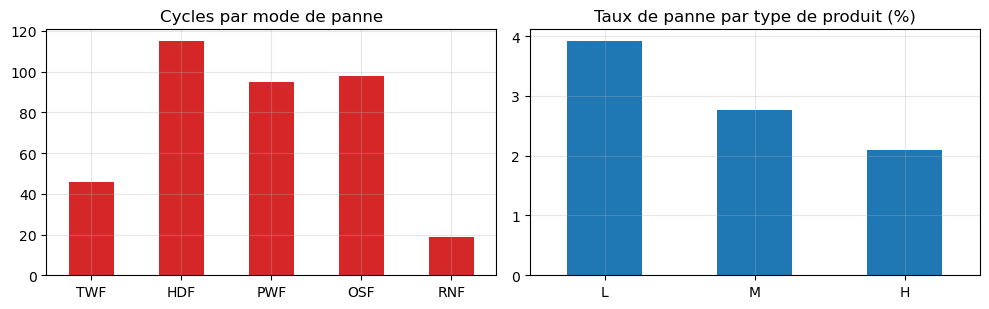

taux de panne par type (%) : {'L': 3.92, 'M': 2.77, 'H': 2.09}


In [4]:
n_modes = df[MODES].sum(axis=1)
print(f"pannes : {int(df.panne.sum())} cycles sur {len(df)}, soit {df.panne.mean():.2%}")
print(f"un modèle qui répond toujours « normal » a une exactitude de {1 - df.panne.mean():.2%}, et un rappel nul")
print("cycles par mode :", df[MODES].sum().to_dict())
print(f"pannes avec plusieurs modes : {int(((df.panne == 1) & (n_modes > 1)).sum())}")
print(f"pannes sans aucun mode : {int(((df.panne == 1) & (n_modes == 0)).sum())}")
print(f"RNF : {int(df.RNF.sum())} cycles, dont {int(df.panne[df.RNF == 1].sum())} seulement marqué « panne »")

taux = df.groupby("Type").panne.mean().reindex(["L", "M", "H"]) * 100
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
df[MODES].sum().plot.bar(ax=ax[0], color="tab:red"); ax[0].set_title("Cycles par mode de panne")
taux.plot.bar(ax=ax[1], color="tab:blue"); ax[1].set_title("Taux de panne par type de produit (%)")
for a in ax:
    a.tick_params(axis="x", rotation=0); a.set_xlabel("")
plt.tight_layout(); plt.show()
print("taux de panne par type (%) :", taux.round(2).to_dict())

**À retenir.**

- Une panne pour 30 cycles environ. L'**exactitude** (*accuracy*) ne veut rien dire ici : un modèle qui ne prédit jamais de panne dépasse 96 %. On mesure donc la **précision**, le **rappel**, le **F1** et la **précision moyenne** (AP).
- Les étiquettes ne sont pas parfaites : quelques pannes n'ont aucun mode, et presque tous les RNF ne sont pas marqués comme pannes. Un modèle ne peut pas retrouver une panne tirée au hasard.
- Les produits L tombent plus souvent en panne : leur seuil de surcharge (OSF) est le plus bas.

### 4.2 Distributions : cycles normaux et pannes

Les histogrammes sont normalisés (densités) : sinon, les 339 pannes seraient invisibles à côté des 9 661 cycles normaux.

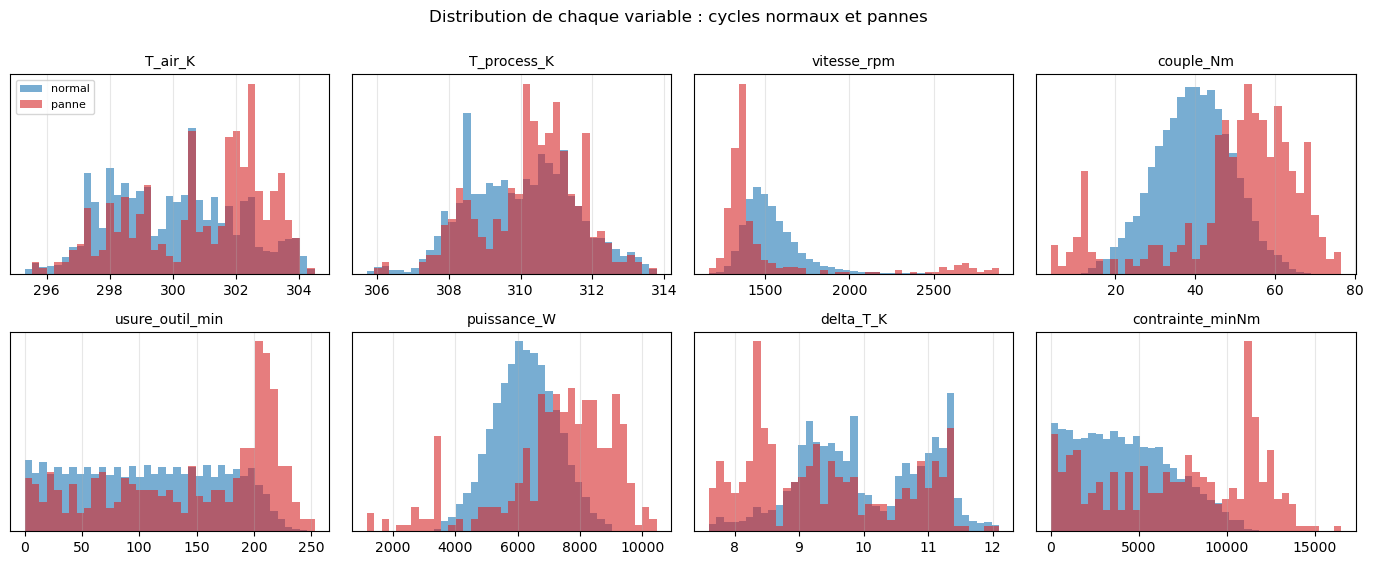

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.6))
for ax, col in zip(axes.ravel(), MESURES + METIER):
    bornes = np.linspace(df[col].min(), df[col].max(), 40)
    ax.hist(df.loc[df.panne == 0, col], bins=bornes, density=True, alpha=0.6, label="normal")
    ax.hist(df.loc[df.panne == 1, col], bins=bornes, density=True, alpha=0.6, color="tab:red", label="panne")
    ax.set_title(col, fontsize=10); ax.set_yticks([])
axes[0, 0].legend(fontsize=8)
plt.suptitle("Distribution de chaque variable : cycles normaux et pannes", y=1.0)
plt.tight_layout(); plt.show()

**À observer.** Les pannes se concentrent aux **extrémités** : vitesse et couple très bas ou très hauts (PWF), forte usure (TWF, OSF), faible écart de température (HDF), forte contrainte (OSF). Une variable seule ne sépare pas les deux classes ; une **combinaison** de variables (puissance, contrainte) les sépare beaucoup mieux.

### 4.3 Corrélations

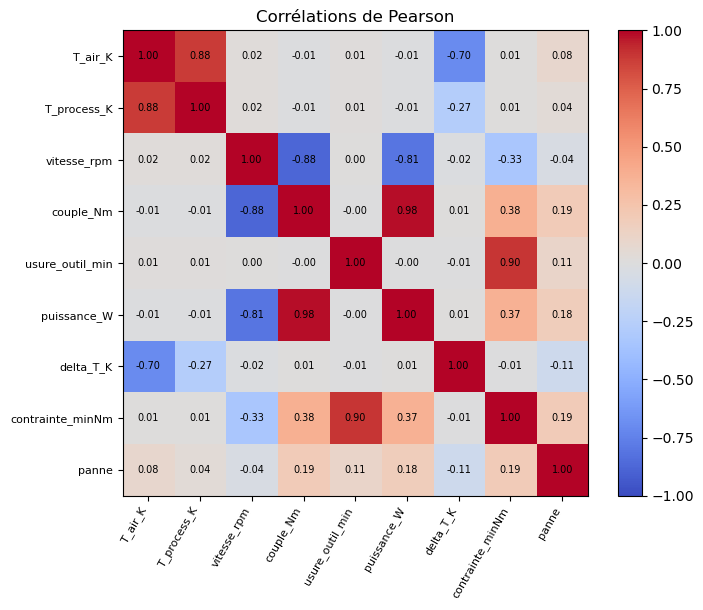

corrélation avec la panne : {'T_air_K': 0.083, 'T_process_K': 0.036, 'vitesse_rpm': -0.044, 'couple_Nm': 0.191, 'usure_outil_min': 0.105, 'puissance_W': 0.176, 'delta_T_K': -0.112, 'contrainte_minNm': 0.19}


In [6]:
corr = df[MESURES + METIER + ["panne"]].corr()
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
for i_ in range(len(corr)):
    for j_ in range(len(corr)):
        ax.text(j_, i_, f"{corr.iloc[i_, j_]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False); plt.colorbar(im, fraction=0.046); ax.set_title("Corrélations de Pearson")
plt.tight_layout(); plt.show()
print("corrélation avec la panne :", corr.panne.drop("panne").round(3).to_dict())

**À observer.**

- Vitesse et couple sont fortement **anti-corrélés** : la vitesse est calculée à partir d'une puissance à peu près constante. Les deux températures sont fortement corrélées : $T_{process}$ suit $T_{air}$.
- Aucune variable n'est fortement corrélée à la panne. La corrélation de Pearson mesure une relation **linéaire**, alors que les pannes viennent de **seuils** (« si $P > 9\,000$ W ») et de **produits** de variables : il faut un modèle non linéaire.

### 4.4 Les règles du générateur, vérifiées sur les données

On applique les règles du tableau 3.6 et on compte les désaccords avec les étiquettes. Puis on trace chaque règle : chaque mode de panne occupe une région délimitée par une courbe.

mode  regle_vraie  etiquette  desaccords
 HDF          115        115           0
 PWF           95         95           0
 OSF           98         98           0
TWF : 46 pannes, à une usure comprise entre 198 et 253 min


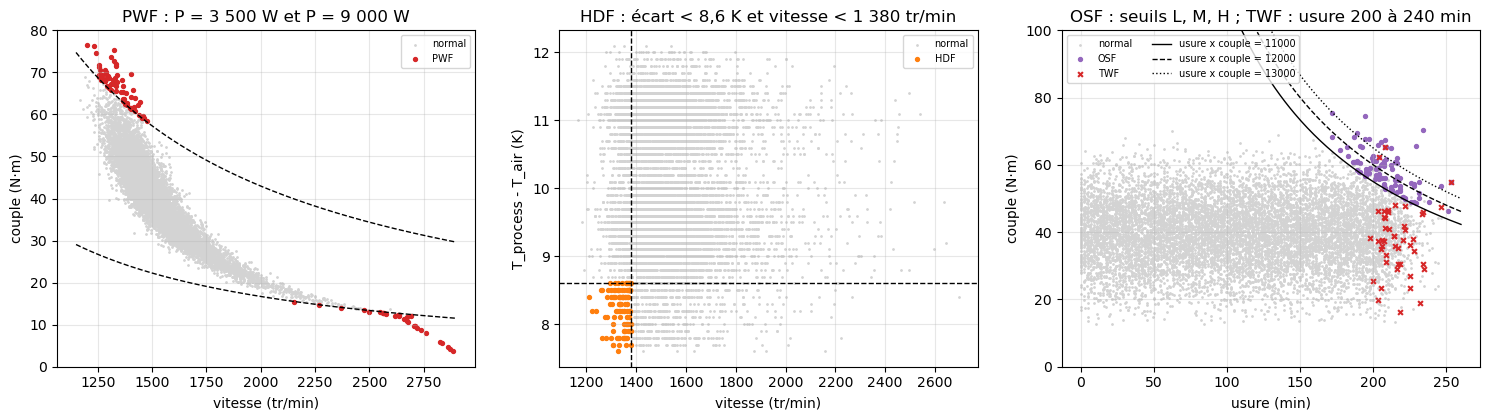

In [7]:
SEUIL_OSF = df.Type.map({"L": 11000, "M": 12000, "H": 13000})
regles = {"HDF": (df.delta_T_K < 8.6) & (df.vitesse_rpm < 1380),
          "PWF": (df.puissance_W < 3500) | (df.puissance_W > 9000),
          "OSF": df.contrainte_minNm > SEUIL_OSF}
print(pd.DataFrame([dict(mode=m, regle_vraie=int(r.sum()), etiquette=int(df[m].sum()),
                         desaccords=int((r != (df[m] == 1)).sum())) for m, r in regles.items()]).to_string(index=False))
twf = df.usure_outil_min[df.TWF == 1]
print(f"TWF : {len(twf)} pannes, à une usure comprise entre {twf.min()} et {twf.max()} min")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
normal = df.panne == 0
n_ = np.linspace(1150, 2900, 200)
ax[0].scatter(df.vitesse_rpm[normal], df.couple_Nm[normal], s=1, c="lightgray", label="normal")
ax[0].scatter(df.vitesse_rpm[df.PWF == 1], df.couple_Nm[df.PWF == 1], s=8, c="tab:red", label="PWF")
for p_ in (3500, 9000):
    ax[0].plot(n_, p_ / (n_ * 2 * np.pi / 60), "k--", lw=1)
ax[0].set_ylim(0, 80); ax[0].set_xlabel("vitesse (tr/min)"); ax[0].set_ylabel("couple (N·m)")
ax[0].set_title("PWF : P = 3 500 W et P = 9 000 W")

ax[1].scatter(df.vitesse_rpm[normal], df.delta_T_K[normal], s=1, c="lightgray", label="normal")
ax[1].scatter(df.vitesse_rpm[df.HDF == 1], df.delta_T_K[df.HDF == 1], s=8, c="tab:orange", label="HDF")
ax[1].axhline(8.6, color="k", ls="--", lw=1); ax[1].axvline(1380, color="k", ls="--", lw=1)
ax[1].set_xlabel("vitesse (tr/min)"); ax[1].set_ylabel("T_process - T_air (K)")
ax[1].set_title("HDF : écart < 8,6 K et vitesse < 1 380 tr/min")

u_ = np.linspace(40, 260, 200)
ax[2].scatter(df.usure_outil_min[normal], df.couple_Nm[normal], s=1, c="lightgray", label="normal")
ax[2].scatter(df.usure_outil_min[df.OSF == 1], df.couple_Nm[df.OSF == 1], s=8, c="tab:purple", label="OSF")
ax[2].scatter(twf, df.couple_Nm[df.TWF == 1], s=12, marker="x", c="tab:red", label="TWF")
for s_, style in [(11000, "-"), (12000, "--"), (13000, ":")]:
    ax[2].plot(u_, s_ / u_, "k", ls=style, lw=1, label=f"usure x couple = {s_}")
ax[2].set_ylim(0, 80); ax[2].set_xlabel("usure (min)"); ax[2].set_ylabel("couple (N·m)")
ax[2].set_title("OSF : seuils L, M, H ; TWF : usure 200 à 240 min")
ax[0].legend(fontsize=7, loc="upper right"); ax[1].legend(fontsize=7, loc="upper right")
ax[2].set_ylim(0, 100); ax[2].legend(fontsize=7, loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

**À retenir.** Les règles HDF, PWF et OSF reproduisent les étiquettes **sans un seul désaccord**. Une panne AI4I est donc, presque toujours, une fonction **du cycle courant** : vitesse, couple, températures et usure de ce cycle-là. Seuls TWF (usure tirée au hasard dans un intervalle), RNF et les pannes sans mode échappent à une règle exacte. Gardez ce constat en tête : il explique les résultats de la section 7.

On note aussi que les TWF observées vont un peu au-delà de l'intervalle annoncé de 200 à 240 min.

### 4.5 La structure temporelle

Les lignes sont dans l'ordre de production : `UDI` est un axe du temps. Quelles variables ont une **mémoire**, c'est-à-dire dépendent des cycles précédents ?

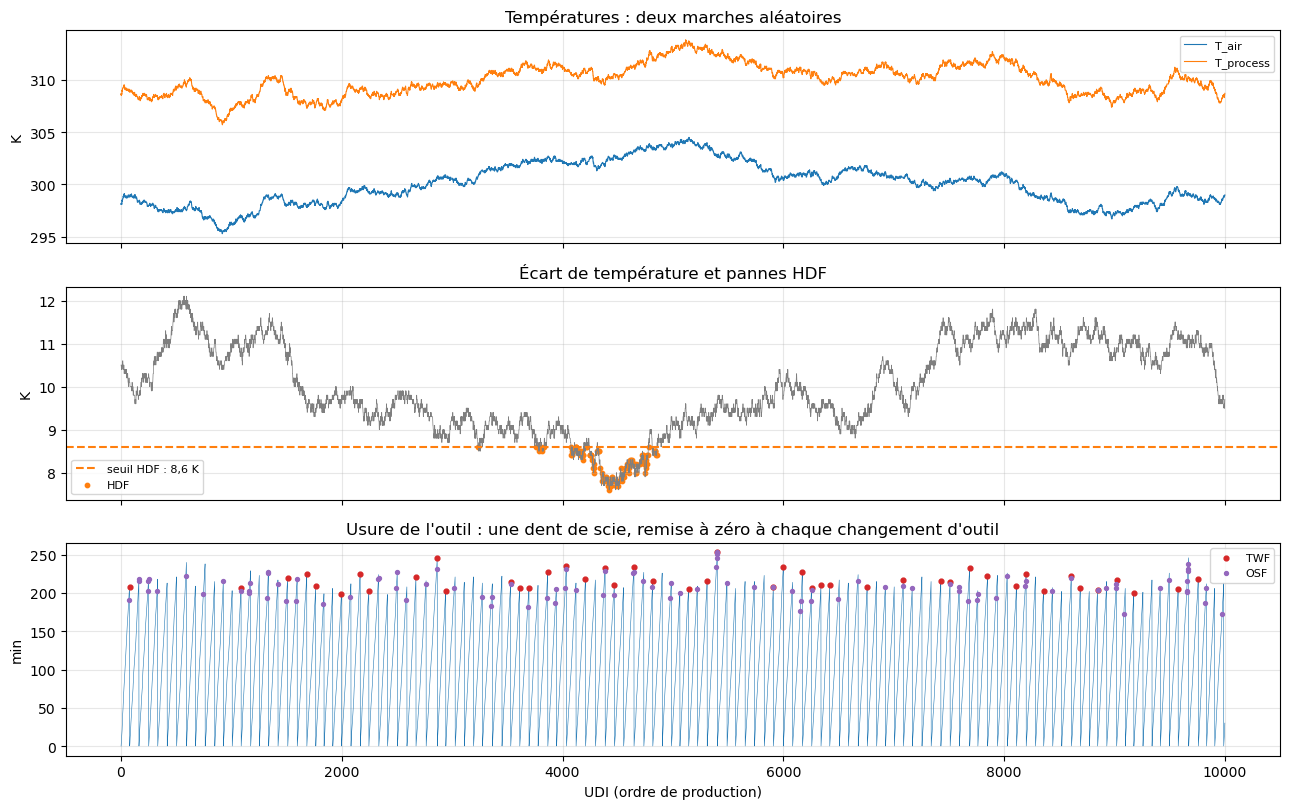

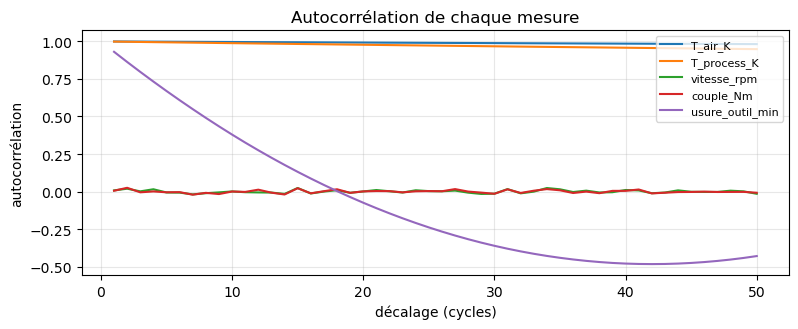

                  décalage 1  décalage 10  décalage 50
T_air_K                0.999        0.996        0.982
T_process_K            0.999        0.988        0.948
vitesse_rpm            0.008        0.001       -0.015
couple_Nm              0.005        0.000       -0.008
usure_outil_min        0.931        0.379       -0.430
puissance_W            0.001        0.005       -0.005
delta_T_K              0.997        0.990        0.960
contrainte_minNm       0.754        0.312       -0.342


In [8]:
fig, ax = plt.subplots(3, 1, figsize=(13, 8.2), sharex=True)
ax[0].plot(df.UDI, df.T_air_K, lw=0.8, label="T_air"); ax[0].plot(df.UDI, df.T_process_K, lw=0.8, label="T_process")
ax[0].set_ylabel("K"); ax[0].legend(fontsize=8); ax[0].set_title("Températures : deux marches aléatoires")
ax[1].plot(df.UDI, df.delta_T_K, lw=0.5, color="tab:gray")
ax[1].axhline(8.6, color="tab:orange", ls="--", label="seuil HDF : 8,6 K")
ax[1].scatter(df.UDI[df.HDF == 1], df.delta_T_K[df.HDF == 1], s=10, color="tab:orange", label="HDF")
ax[1].set_ylabel("K"); ax[1].legend(fontsize=8); ax[1].set_title("Écart de température et pannes HDF")
ax[2].plot(df.UDI, df.usure_outil_min, lw=0.4)
ax[2].scatter(df.UDI[df.TWF == 1], df.usure_outil_min[df.TWF == 1], s=12, color="tab:red", label="TWF", zorder=3)
ax[2].scatter(df.UDI[df.OSF == 1], df.usure_outil_min[df.OSF == 1], s=8, color="tab:purple", label="OSF", zorder=3)
ax[2].set_ylabel("min"); ax[2].set_xlabel("UDI (ordre de production)"); ax[2].legend(fontsize=8)
ax[2].set_title("Usure de l'outil : une dent de scie, remise à zéro à chaque changement d'outil")
plt.tight_layout(); plt.show()

decalages = range(1, 51)
fig, ax = plt.subplots(figsize=(8, 3.4))
for col in MESURES:
    ax.plot(decalages, [df[col].autocorr(k) for k in decalages], label=col)
ax.set_xlabel("décalage (cycles)"); ax.set_ylabel("autocorrélation"); ax.legend(fontsize=8)
ax.set_title("Autocorrélation de chaque mesure")
plt.tight_layout(); plt.show()
print(pd.DataFrame({k: [round(df[c].autocorr(k), 3) for c in MESURES + METIER] for k in (1, 10, 50)},
                   index=MESURES + METIER).rename(columns=lambda k: f"décalage {k}").to_string())

L'usure suit-elle exactement la règle « chaque produit ajoute 2, 3 ou 5 minutes » ? On repère les changements d'outil (l'usure retombe à 0), puis on reconstruit l'usure produit par produit. Deux hypothèses : l'incrément vient du type du produit **courant**, ou du type du produit **précédent**.

In [9]:
INCREMENT = {"L": 2, "M": 3, "H": 5}
usure = df.usure_outil_min.values
outil = np.r_[0, np.cumsum(np.diff(usure) < 0)]       # un nouvel outil chaque fois que l'usure retombe
debut = np.r_[True, np.diff(outil) > 0]                # premier cycle de chaque outil
df["outil"] = outil
vie = df.groupby("outil").size()
print(f"{len(vie)} outils, durée de vie de {vie.min()} à {vie.max()} cycles (moyenne {vie.mean():.1f})")
print("usure au premier cycle de chaque outil :", sorted(set(usure[debut].tolist())))

for nom, decalage in [("type du produit courant", 0), ("type du produit précédent", 1)]:
    inc = np.array(df.Type.map(INCREMENT).shift(decalage).fillna(0), dtype=float)
    inc[debut] = 0                                     # l'usure repart de 0 au changement d'outil
    reconstruite = pd.Series(inc).groupby(outil).cumsum().values
    print(f"incrément = {nom:26s}: écart maximal {int(np.abs(reconstruite - usure).max())} min, "
          f"{int((reconstruite != usure).sum())} cycles en désaccord")

120 outils, durée de vie de 11 à 101 cycles (moyenne 83.3)
usure au premier cycle de chaque outil : [0]
incrément = type du produit courant   : écart maximal 3 min, 5488 cycles en désaccord
incrément = type du produit précédent : écart maximal 0 min, 0 cycles en désaccord


**À retenir.**

- Les **températures** sont des marches aléatoires : autocorrélation de 0,99 même à 10 cycles. Elles varient lentement, et l'écart $\Delta T$ ne passe sous 8,6 K que pendant une seule période : toutes les HDF y sont regroupées.
- **Vitesse** et **couple** n'ont **aucune mémoire** : autocorrélation nulle. Chaque produit est tiré indépendamment du précédent.
- L'**usure** est une dent de scie : 120 outils, de 11 à 101 cycles chacun. Elle obéit **exactement** à une récurrence, $u_t = u_{t-1} + \text{incrément}(\text{type}_{t-1})$, remise à zéro à chaque changement d'outil. L'usure du cycle $t$ résume donc tout le passé de l'outil. C'est exactement ce que fait l'état caché d'un réseau récurrent : la section 8 s'en sert.

### 4.6 Conséquence : comment découper les données ?

Trois façons de séparer apprentissage, validation et test :

1. **Au hasard, ligne par ligne** (labs 1 et 3). Avec des fenêtres glissantes, la fenêtre d'un cycle de test recouvre des cycles d'apprentissage : c'est une **fuite d'information**.
2. **Dans l'ordre du temps** (70 % puis 15 % puis 15 %). C'est la règle pour une série temporelle. Regardons ce que cela donne ici.
3. **Par outil** : on tire au hasard 70 % des 120 outils pour l'apprentissage, 15 % pour la validation et 15 % pour le test. Chaque vie d'outil est un bloc de cycles consécutifs, qui reste entier.

In [10]:
chrono = np.where(df.UDI <= 7000, "apprentissage", np.where(df.UDI <= 8500, "validation", "test"))
print("Découpage chronologique :")
print(df.groupby(chrono, sort=False)[["panne"] + MODES].sum().T.to_string())
print("écart de température minimal :", df.groupby(chrono, sort=False).delta_T_K.min().round(1).to_dict())

rng = np.random.default_rng(SEED)
ordre_outils = rng.permutation(len(vie))
n_o = len(ordre_outils)
PARTITION = {int(o): ("apprentissage" if k < int(0.70 * n_o) else "validation" if k < int(0.85 * n_o) else "test")
             for k, o in enumerate(ordre_outils)}
df["partition"] = df.outil.map(PARTITION)
print("\nDécoupage par outil :")
ORDRE = ["apprentissage", "validation", "test"]
resume = df.groupby("partition").agg(outils=("outil", "nunique"), cycles=("panne", "size"), pannes=("panne", "sum"))
print(pd.concat([resume, df.groupby("partition")[MODES].sum()], axis=1).reindex(ORDRE).T.to_string())

Découpage chronologique :
       apprentissage  validation  test
panne            278          32    29
TWF               31           8     7
HDF              115           0     0
PWF               76          12     7
OSF               68          13    17
RNF               17           2     0
écart de température minimal : {'apprentissage': 7.6, 'validation': 9.3, 'test': 9.5}

Découpage par outil :
partition  apprentissage  validation  test
outils                84          18    18
cycles              6977        1525  1498
pannes               243          57    39
TWF                   33           9     4
HDF                   76          30     9
PWF                   73           7    15
OSF                   75          12    11
RNF                    9           1     9


**À retenir.** Le découpage chronologique laisse **zéro panne HDF** en validation et en test : après le cycle 7 000, l'air est plus frais et l'écart de température ne descend jamais sous 8,6 K. Un modèle serait alors évalué sans jamais rencontrer un mode de panne entier. C'est une **dérive** des conditions de fonctionnement (lab 1).

On retient donc le **découpage par outil**. Il garde des blocs consécutifs (pas de fuite entre fenêtres voisines, à part les quelques cycles de contexte au début de chaque bloc, qui sont des entrées et jamais des étiquettes), et chaque partition contient tous les modes de panne. Le test ne contient que 39 pannes : un écart de 2 à 3 points de F1 entre deux modèles n'est pas significatif.

## 5. Des cycles aux séquences : les fenêtres glissantes

Le modèle reçoit, pour décider au cycle $t$, la **fenêtre** des $T$ derniers cycles $(\mathbf{x}_{t-T+1}, \dots, \mathbf{x}_t)$, et doit dire si le cycle $t$ est une panne : c'est une architecture **plusieurs vers un** (*many-to-one*). Chaque $\mathbf{x}$ contient $d = 11$ variables : les 5 mesures, les 3 variables métier et le type en *one-hot*.

- Les variables sont **centrées et réduites** avec la moyenne et l'écart-type de l'**apprentissage seul**.
- Les fenêtres des premiers cycles sont complétées en répétant le premier cycle, pour que tous les modèles soient évalués sur **exactement les mêmes cycles**, quel que soit $T$.
- Longueur par défaut : $T = 10$ cycles. La section 7.1 fait varier $T$.

In [11]:
ENTREES = MESURES + METIER + ["Type_H", "Type_L", "Type_M"]
X_tab = pd.get_dummies(df[MESURES + METIER + ["Type"]], columns=["Type"], dtype=float)[ENTREES].values.astype(np.float32)
y_tab = df.panne.values.astype(np.float32)
m_app, m_val, m_test = (df.partition.values == p for p in ("apprentissage", "validation", "test"))
mu, sd = X_tab[m_app].mean(0), X_tab[m_app].std(0)     # statistiques de l'apprentissage seul
X_norm = (X_tab - mu) / sd
D = len(ENTREES)

def fenetres(X, T):
    # fenêtre du cycle t : cycles t-T+1, ..., t ; le début de la série est complété par le premier cycle
    Xp = np.pad(X, ((T - 1, 0), (0, 0)), mode="edge")
    return np.lib.stride_tricks.sliding_window_view(Xp, (T, X.shape[1]))[:, 0].copy()

def jeux(T):
    W, y = torch.tensor(fenetres(X_norm, T)), torch.tensor(y_tab)
    return {"app": (W[m_app], y[m_app]), "val": (W[m_val], y[m_val]), "test": (W[m_test], y[m_test])}

T_FEN = 10
J10 = jeux(T_FEN)
y_val_np, y_test_np = J10["val"][1].numpy(), J10["test"][1].numpy()
for p_, (W_, y_) in J10.items():
    print(f"{p_:5s} : fenêtres {tuple(W_.shape)} = (cycles, T, d), {int(y_.sum())} pannes")
assert torch.allclose(J10["app"][0][:, -1], torch.tensor(X_norm[m_app]))   # le dernier pas de la fenêtre est le cycle courant

t_ex = int(np.where((df.OSF.values == 1) & m_test)[0][0])
print(f"\nCe que voit le modèle pour le cycle {t_ex + 1} (UDI), une panne OSF du test (valeurs avant normalisation) :")
df.loc[t_ex - T_FEN + 1:t_ex, ["UDI", "Type"] + MESURES + ["contrainte_minNm", "panne"]]

app   : fenêtres (6977, 10, 11) = (cycles, T, d), 243 pannes
val   : fenêtres (1525, 10, 11) = (cycles, T, d), 57 pannes
test  : fenêtres (1498, 10, 11) = (cycles, T, d), 39 pannes

Ce que voit le modèle pour le cycle 747 (UDI), une panne OSF du test (valeurs avant normalisation) :


,UDI,Type,T_air_K,T_process_K,vitesse_rpm,couple_Nm,usure_outil_min,contrainte_minNm,panne
737,738,H,296.9,308.3,1474,39.2,177,6938.4,0
738,739,L,296.8,308.3,1506,45.9,182,8353.8,0
739,740,L,296.9,308.4,1390,41.8,184,7691.2,0
740,741,M,296.9,308.4,1450,46.9,186,8723.4,0
741,742,L,296.9,308.3,1513,38.8,189,7333.2,0
742,743,L,296.8,308.2,1643,34.7,191,6627.7,0
743,744,L,296.8,308.2,1361,53.8,193,10383.4,0
744,745,L,296.7,308.1,1450,40.9,195,7975.5,0
745,746,L,296.7,308.0,1451,50.7,197,9987.9,0
746,747,L,296.8,308.1,1289,62.0,199,12338.0,1


**Lire la forme `(cycles, T, d)`.** Les fenêtres sont rangées dans un tenseur à trois dimensions, par exemple `(6977, 10, 11)` pour l'apprentissage :

| Dimension | Taille | Signification |
|---|---|---|
| `cycles` | 6 977 | **une fenêtre par cycle à classer** : autant de fenêtres que de cycles dans la partition, chacune avec son étiquette (panne ou non) |
| `T` | 10 | **les pas de temps** de la fenêtre : le cycle courant $t$ et les 9 cycles qui le précèdent, du plus ancien ($t-9$) au plus récent ($t$) |
| `d` | 11 | **les variables** de chaque pas : 5 mesures, 3 variables métier et les 3 colonnes du type |

- `W[k]` est une matrice $10 \times 11$ : la fenêtre du $k$-ième cycle. Le tableau affiché ci-dessus pour le cycle 747 en est une version lisible, avant normalisation : 10 lignes, une par cycle.
- `W[k, -1]` est le vecteur $\mathbf{x}_t$ du cycle courant, et `W[k, 0]` celui du cycle $t-9$. `W[:, :, 3]` donne le couple (4<sup>e</sup> variable) à tous les pas de toutes les fenêtres.
- Un même cycle apparaît dans 10 fenêtres successives : en position $t$ dans sa propre fenêtre, en position $t-1$ dans celle du cycle suivant, et ainsi de suite. Le tenseur contient donc 10 fois plus de valeurs que le tableau : $6\,977 \times 10 \times 11 = 767\,470$ nombres.
- C'est la forme qu'attendent `nn.RNN`, `nn.LSTM` et `nn.GRU` avec `batch_first=True` : (lot, longueur de séquence, variables). Pendant l'entraînement, un lot de 64 fenêtres a la forme `(64, 10, 11)`. Le réseau lit les 10 pas l'un après l'autre et renvoie un état caché par pas, soit un tenseur `(64, 10, 32)`, dont on garde le dernier pas.
- En section 8, la même logique donne la forme `(outils, cycles, d)`, par exemple `(84, 101, 7)` : une séquence par outil, de 101 pas au plus (les outils plus courts sont complétés par des zéros), avec 7 variables par pas.

## 6. RNN, LSTM, GRU : formules, modèles et paramètres

Rappel de la séance 4. $\mathbf{x}_t$ est le vecteur des $d$ variables du cycle $t$, $\mathbf{h}_t$ l'état caché de taille $h$, $\sigma$ la sigmoïde.

| Cellule | Formules |
|---|---|
| RNN | $\mathbf{h}_t = \tanh\big(W_{xh}\,\mathbf{x}_t + W_{hh}\,\mathbf{h}_{t-1} + \mathbf{b}\big)$ |
| LSTM | portes $\mathbf{f}_t, \mathbf{i}_t, \mathbf{o}_t = \sigma(\cdot)$ et candidat $\tilde{\mathbf{c}}_t = \tanh(\cdot)$, avec pour chacun $(\cdot) = W\mathbf{x}_t + U\mathbf{h}_{t-1} + \mathbf{b}$ ; mémoire $\mathbf{c}_t = \mathbf{f}_t \odot \mathbf{c}_{t-1} + \mathbf{i}_t \odot \tilde{\mathbf{c}}_t$ ; sortie $\mathbf{h}_t = \mathbf{o}_t \odot \tanh(\mathbf{c}_t)$ |
| GRU (convention PyTorch) | $\mathbf{h}_t = (1-\mathbf{z}_t)\odot\mathbf{n}_t + \mathbf{z}_t\odot\mathbf{h}_{t-1}$ |

| Coût | RNN | GRU | LSTM |
|---|---|---|---|
| Paramètres (PyTorch) | $h(d+h+2)$ | $3h(d+h+2)$ | $4h(d+h+2)$ |
| MAC par pas de temps | $h(d+h)$ | $3h(d+h)$ | $4h(d+h)$ |

Le « +2 » vient des deux vecteurs de biais que PyTorch alloue par bloc (porte ou candidat). La tête linéaire $h \to 1$ ajoute $h + 1$ paramètres.

Cinq modèles, tous terminés par une sortie unique, le **logit** $z$ ; la probabilité de panne est $\hat{y} = \sigma(z)$.

| Modèle | Ce qu'il lit | Mémoire |
|---|---|---|
| MLP, dernier cycle | $\mathbf{x}_t$ seul : le MLP du lab 3, $11 \to 64 \to 32 \to 1$ | aucune |
| MLP, fenêtre à plat | les $T \times d$ valeurs de la fenêtre, mises bout à bout | un poids par variable **et par position** |
| RNN, LSTM, GRU | la fenêtre, un cycle à la fois, avec les **mêmes poids** à chaque pas ; la tête linéaire lit le dernier état $\mathbf{h}_t$ | l'état caché ($h = 32$) |

On compte les paramètres par la formule, puis on vérifie avec PyTorch, pour trois longueurs de fenêtre.

In [12]:
def mlp(n_entrees, cachees=(64, 32)):
    couches, d_ = [], n_entrees
    for h_ in cachees:
        couches += [nn.Linear(d_, h_), nn.ReLU()]
        d_ = h_
    couches.append(nn.Linear(d_, 1))
    return nn.Sequential(*couches)

class MLPDernierCycle(nn.Module):
    # sans mémoire : ne lit que le dernier cycle de la fenêtre
    def __init__(self, d):
        super().__init__(); self.net = mlp(d)
    def forward(self, x):                      # x : (lot, T, d)
        return self.net(x[:, -1]).squeeze(1)

class MLPFenetre(nn.Module):
    # la fenêtre mise à plat : T x d entrées
    def __init__(self, d, T):
        super().__init__(); self.net = mlp(d * T)
    def forward(self, x):
        return self.net(x.flatten(1)).squeeze(1)

class Recurrent(nn.Module):
    # RNN, LSTM ou GRU lu sur la fenêtre, puis une tête linéaire sur le dernier état caché
    def __init__(self, cell, d, h=32):
        super().__init__()
        self.rnn = CLASSES[cell](d, h, batch_first=True)
        self.tete = nn.Linear(h, 1)
    def forward(self, x):                      # x : (lot, T, d)
        etats, _ = self.rnn(x)                 # etats : (lot, T, h), un état caché par pas de temps
        return self.tete(etats[:, -1]).squeeze(1)

H = 32
FABRIQUES = {"MLP, dernier cycle": lambda T: MLPDernierCycle(D),
             "MLP, fenêtre à plat": lambda T: MLPFenetre(D, T),
             "RNN": lambda T: Recurrent("rnn", D, H),
             "LSTM": lambda T: Recurrent("lstm", D, H),
             "GRU": lambda T: Recurrent("gru", D, H)}

def params_mlp(n_entrees, cachees=(64, 32)):
    tailles = [n_entrees, *cachees, 1]
    return sum(a * b + b for a, b in zip(tailles[:-1], tailles[1:]))

FORMULES = {"MLP, dernier cycle": lambda T: params_mlp(D),
            "MLP, fenêtre à plat": lambda T: params_mlp(D * T),
            "RNN": lambda T: 1 * H * (D + H + 2) + H + 1,
            "LSTM": lambda T: 4 * H * (D + H + 2) + H + 1,
            "GRU": lambda T: 3 * H * (D + H + 2) + H + 1}
lignes = []
for nom, fab in FABRIQUES.items():
    ligne = {"modèle": nom}
    for T in (1, 10, 30):
        n = nb_params(fab(T))
        assert n == FORMULES[nom](T)
        ligne[f"T = {T}"] = n
    lignes.append(ligne)
print(f"Paramètres (d = {D}, h = {H}) ; formule et PyTorch coïncident (assertion vérifiée) :")
print(pd.DataFrame(lignes).to_string(index=False))

print("\nDétail du LSTM (les 4 blocs i, f, g, o sont empilés, d'où 4 x 32 = 128 lignes) :")
for nom, p_ in Recurrent("lstm", D, H).named_parameters():
    print(f"  {nom:16s} {str(tuple(p_.shape)):10s} {p_.numel():5d}")

Paramètres (d = 11, h = 32) ; formule et PyTorch coïncident (assertion vérifiée) :
             modèle  T = 1  T = 10  T = 30
 MLP, dernier cycle   2881    2881    2881
MLP, fenêtre à plat   2881    9217   23297
                RNN   1473    1473    1473
               LSTM   5793    5793    5793
                GRU   4353    4353    4353

Détail du LSTM (les 4 blocs i, f, g, o sont empilés, d'où 4 x 32 = 128 lignes) :
  rnn.weight_ih_l0 (128, 11)   1408
  rnn.weight_hh_l0 (128, 32)   4096
  rnn.bias_ih_l0   (128,)       128
  rnn.bias_hh_l0   (128,)       128
  tete.weight      (1, 32)       32
  tete.bias        (1,)           1


**À observer.** La taille du MLP à plat **croît avec $T$** ; celle des réseaux récurrents **ne dépend pas de $T$**. Pour un même $h$, le LSTM a 4 fois les paramètres de la cellule RNN, et le GRU 3 fois.

## 7. Détecter les pannes : entraîner et évaluer

Les mesures utilisées (séances 2 et 3) :

| Mesure | Formule | Ce qu'elle dit |
|---|---|---|
| Perte | $\mathcal{L} = -\big[y\ln\hat{y} + (1-y)\ln(1-\hat{y})\big]$, avec $\hat{y} = \sigma(z)$ | entropie croisée binaire (*binary cross-entropy*) |
| Précision (*precision*) | $P = \dfrac{TP}{TP+FP}$ | parmi les alertes, la part de vraies pannes |
| Rappel (*recall*) | $R = \dfrac{TP}{TP+FN}$ | parmi les pannes, la part détectée |
| F1 | $F_1 = \dfrac{2PR}{P+R}$ | le compromis entre les deux, à un seuil donné |
| Précision moyenne (*average precision*, AP) | $\mathrm{AP} = \sum_k (R_k - R_{k-1})\,P_k$ | l'aire sous la courbe précision-rappel, tous seuils confondus |

Protocole commun à tous les modèles :

- perte : entropie croisée binaire (`BCEWithLogitsLoss`), **sans pondération** des classes (au lab 3, la pondération n'a pas amélioré le F1 une fois le seuil choisi) ;
- Adam, $\eta = 3\times 10^{-3}$, lots de 64 fenêtres, écrêtage du gradient à 5 ;
- **arrêt précoce** : on garde l'époque qui maximise l'AP de **validation** (patience de 20 époques, 150 au plus) ;
- **seuil de décision** choisi sur la validation pour maximiser le F1, puis appliqué tel quel au test ;
- **3 graines** par modèle : on donne la moyenne et l'écart-type.

Référence : la **forêt aléatoire** des labs 1 et 3 (200 arbres), entraînée sur le dernier cycle avec les mêmes partitions.

In [13]:
SEUILS = np.round(np.arange(0.05, 0.96, 0.05), 2)
GRAINES = (0, 1, 2)

def probas(modele, X):
    modele.eval()
    with torch.no_grad():
        return torch.sigmoid(modele(X)).numpy()

def entrainer_detecteur(fabrique, J, graine, epoques_max=150, patience=20, lr=3e-3, taille_lot=64):
    torch.manual_seed(graine)
    modele = fabrique()
    (Xa, ya), (Xv, yv) = J["app"], J["val"]
    opt = torch.optim.Adam(modele.parameters(), lr=lr)
    perte = nn.BCEWithLogitsLoss()
    gen = torch.Generator().manual_seed(graine)
    meilleur, etat, attente, ep_best = -1.0, None, 0, 0
    t0 = time.time()
    for ep in range(1, epoques_max + 1):
        modele.train()
        ordre = torch.randperm(len(Xa), generator=gen)
        for i_ in range(0, len(Xa), taille_lot):
            idx = ordre[i_:i_ + taille_lot]
            l = perte(modele(Xa[idx]), ya[idx])
            opt.zero_grad(); l.backward()
            nn.utils.clip_grad_norm_(modele.parameters(), 5.0)   # garde-fou contre l'explosion du gradient
            opt.step()
        ap = average_precision_score(yv.numpy(), probas(modele, Xv))
        if ap > meilleur:
            meilleur, ep_best, attente, etat = ap, ep, 0, copy.deepcopy(modele.state_dict())
        else:
            attente += 1
            if attente >= patience:
                break
    modele.load_state_dict(etat); modele.eval()
    return modele, dict(ap_val=meilleur, epoque=ep_best, duree=time.time() - t0)

def choisir_seuil(p_val, y_val):
    return float(SEUILS[int(np.argmax([f1_score(y_val, p_val > s) for s in SEUILS]))])

def mesurer(p, y, seuil):
    pred = p > seuil
    return dict(AP=average_precision_score(y, p), F1=f1_score(y, pred), rappel=recall_score(y, pred),
                precision=precision_score(y, pred, zero_division=0))

resultats, modeles, p_tests = [], {}, {}
for nom, fab in FABRIQUES.items():
    for g in GRAINES:
        modele, info = entrainer_detecteur(lambda: fab(T_FEN), J10, g)
        seuil = choisir_seuil(probas(modele, J10["val"][0]), y_val_np)
        p = probas(modele, J10["test"][0])
        resultats.append(dict(modele=nom, graine=g, params=nb_params(modele), seuil=seuil, **info, **mesurer(p, y_test_np, seuil)))
        modeles[(nom, g)], p_tests[(nom, g)] = modele, (p, seuil)
    r = pd.DataFrame(resultats); r = r[r.modele == nom]
    print(f"{nom:20s} : AP test {r.AP.mean():.3f} ± {r.AP.std():.3f}   F1 test {r.F1.mean():.3f} ± {r.F1.std():.3f}   "
          f"époque retenue {r.epoque.mean():5.1f}   {r.duree.mean():4.1f} s par entraînement")

t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced",
                            random_state=SEED, n_jobs=-1).fit(X_tab[m_app], y_tab[m_app])
seuil_rf = choisir_seuil(rf.predict_proba(X_tab[m_val])[:, 1], y_val_np)
p_rf = rf.predict_proba(X_tab[m_test])[:, 1]
res_rf = dict(modele="Forêt aléatoire, dernier cycle", params=np.nan, seuil=seuil_rf, duree=time.time() - t0,
              **mesurer(p_rf, y_test_np, seuil_rf))
print(f"{'Forêt aléatoire':20s} : AP test {res_rf['AP']:.3f}   F1 test {res_rf['F1']:.3f}   {res_rf['duree']:.1f} s")

MLP, dernier cycle   : AP test 0.779 ± 0.031   F1 test 0.728 ± 0.024   époque retenue  55.0    2.6 s par entraînement


MLP, fenêtre à plat  : AP test 0.265 ± 0.040   F1 test 0.303 ± 0.038   époque retenue  21.0    1.7 s par entraînement


RNN                  : AP test 0.653 ± 0.007   F1 test 0.603 ± 0.029   époque retenue  28.7    3.7 s par entraînement


LSTM                 : AP test 0.651 ± 0.036   F1 test 0.590 ± 0.029   époque retenue  20.7    6.4 s par entraînement


GRU                  : AP test 0.633 ± 0.034   F1 test 0.590 ± 0.029   époque retenue  29.7    7.2 s par entraînement
Forêt aléatoire      : AP test 0.910   F1 test 0.919   0.2 s


In [14]:
res = pd.DataFrame(resultats)
tab = res.groupby("modele", sort=False).agg(params=("params", "first"), AP=("AP", "mean"), AP_std=("AP", "std"),
                                            F1=("F1", "mean"), F1_std=("F1", "std"), rappel=("rappel", "mean"),
                                            precision=("precision", "mean"), epoque=("epoque", "mean"), duree=("duree", "mean"))
tab.loc["Forêt aléatoire, dernier cycle"] = [np.nan, res_rf["AP"], np.nan, res_rf["F1"], np.nan,
                                             res_rf["rappel"], res_rf["precision"], np.nan, res_rf["duree"]]
affiche = pd.DataFrame({
    "paramètres": tab.params.map(lambda v: "-" if np.isnan(v) else f"{int(v)}"),
    "AP test": [f"{a:.3f}" + ("" if np.isnan(s) else f" ± {s:.3f}") for a, s in zip(tab.AP, tab.AP_std)],
    "F1 test": [f"{a:.3f}" + ("" if np.isnan(s) else f" ± {s:.3f}") for a, s in zip(tab.F1, tab.F1_std)],
    "rappel": tab.rappel.round(3), "précision": tab.precision.round(3),
    "époque retenue": tab.epoque.round(1), "durée (s)": tab.duree.round(1)})
print(f"Fenêtre de T = {T_FEN} cycles, test = {len(y_test_np)} cycles dont {int(y_test_np.sum())} pannes ; moyenne ± écart-type sur 3 graines")
print(affiche.to_string())

Fenêtre de T = 10 cycles, test = 1498 cycles dont 39 pannes ; moyenne ± écart-type sur 3 graines
                               paramètres        AP test        F1 test  rappel  précision  époque retenue  durée (s)
modele                                                                                                               
MLP, dernier cycle                   2881  0.779 ± 0.031  0.728 ± 0.024   0.761      0.701            55.0        2.6
MLP, fenêtre à plat                  9217  0.265 ± 0.040  0.303 ± 0.038   0.316      0.347            21.0        1.7
RNN                                  1473  0.653 ± 0.007  0.603 ± 0.029   0.615      0.603            28.7        3.7
LSTM                                 5793  0.651 ± 0.036  0.590 ± 0.029   0.658      0.538            20.7        6.4
GRU                                  4353  0.633 ± 0.034  0.590 ± 0.029   0.538      0.662            29.7        7.2
Forêt aléatoire, dernier cycle          -          0.910          0.919   0.8

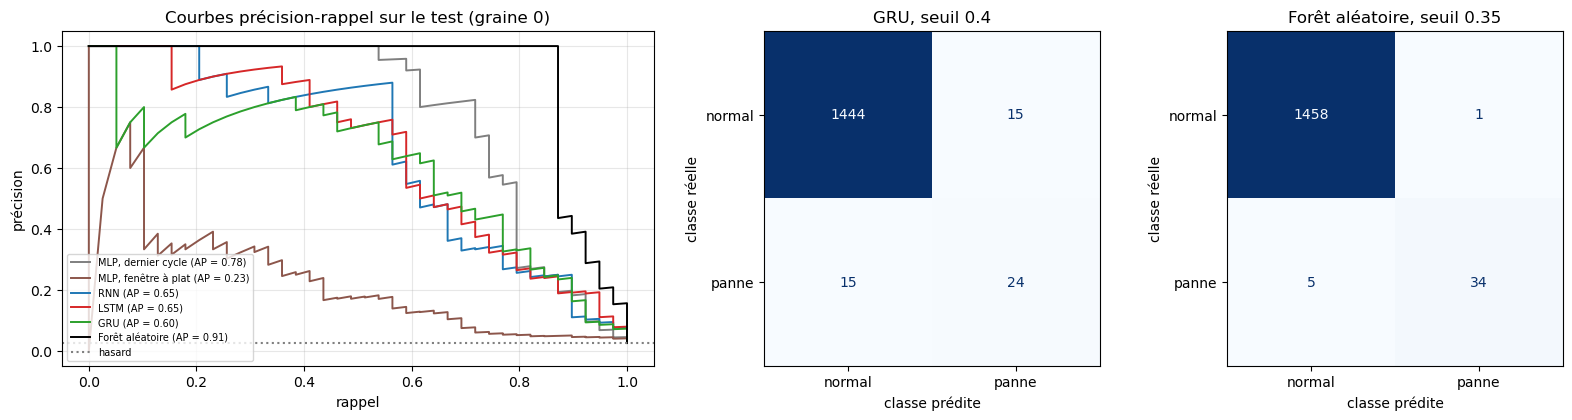

In [15]:
COULEURS = {"MLP, dernier cycle": "tab:gray", "MLP, fenêtre à plat": "tab:brown", "RNN": "tab:blue",
            "LSTM": "tab:red", "GRU": "tab:green", "Forêt aléatoire": "black"}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw={"width_ratios": [1.6, 1, 1]})
for nom, coul in COULEURS.items():
    p = p_rf if nom == "Forêt aléatoire" else p_tests[(nom, 0)][0]
    prec_, rap_, _ = precision_recall_curve(y_test_np, p)
    ax[0].plot(rap_, prec_, color=coul, lw=1.4, label=f"{nom} (AP = {average_precision_score(y_test_np, p):.2f})")
ax[0].axhline(y_test_np.mean(), ls=":", color="gray", label="hasard")
ax[0].set_xlabel("rappel"); ax[0].set_ylabel("précision"); ax[0].legend(fontsize=7)
ax[0].set_title("Courbes précision-rappel sur le test (graine 0)")
for a, (nom, (p, s)) in zip(ax[1:], [("GRU", p_tests[("GRU", 0)]), ("Forêt aléatoire", (p_rf, seuil_rf))]):
    ConfusionMatrixDisplay.from_predictions(y_test_np, (p > s).astype(int), display_labels=["normal", "panne"],
                                            cmap="Blues", ax=a, colorbar=False)
    a.grid(False); a.set_title(f"{nom}, seuil {s}"); a.set_xlabel("classe prédite"); a.set_ylabel("classe réelle")
plt.tight_layout(); plt.show()

**À observer** (les valeurs exactes varient de quelques centièmes selon la machine) :

- **La forêt aléatoire domine** : AP de 0,91, F1 de 0,92, et une seule fausse alerte sur 1 459 cycles normaux. C'est fréquent sur des données tabulaires (Grinsztajn et al., 2022). Ici, en plus, chaque panne vient d'un seuil sur une variable, et c'est exactement ce que découpe un arbre.
- **Le MLP qui ne voit que le cycle courant** (AP de 0,78) bat les trois réseaux récurrents (AP de 0,63 à 0,65), qui voient pourtant 10 cycles.
- **Le MLP à plat s'effondre** (AP de 0,27). Il a un poids par variable et par position, soit 9 217 paramètres pour 243 pannes d'apprentissage : il apprend par cœur le bruit des cycles passés, et l'arrêt précoce le stoppe dès la 21<sup>e</sup> époque en moyenne.
- **RNN, LSTM et GRU font jeu égal** : leurs écarts d'AP (0,02) sont plus petits que les écarts entre graines. Le LSTM et le GRU ont 4 et 3 fois plus de paramètres que le RNN, sans rien gagner.
- Le test ne compte que 39 pannes : une panne de plus ou de moins déplace le rappel de 2,6 points.

### 7.1 Interpréter (1) : la longueur de la fenêtre

Si le passé aidait, allonger la fenêtre devrait améliorer les réseaux récurrents. On entraîne RNN, LSTM et GRU pour $T = 1$, 5, 10 et 20 cycles, 3 graines chacun. Avec $T = 1$, un réseau récurrent n'a aucun passé : c'est un réseau à une couche cachée de 32 neurones.

T =  1 : fait (45 s)


T =  5 : fait (71 s)


T = 20 : fait (160 s)

AP sur le test, moyenne de 3 graines :
modele    RNN   LSTM    GRU
T                          
1       0.767  0.812  0.817
5       0.579  0.623  0.606
10      0.653  0.651  0.633
20      0.592  0.715  0.698


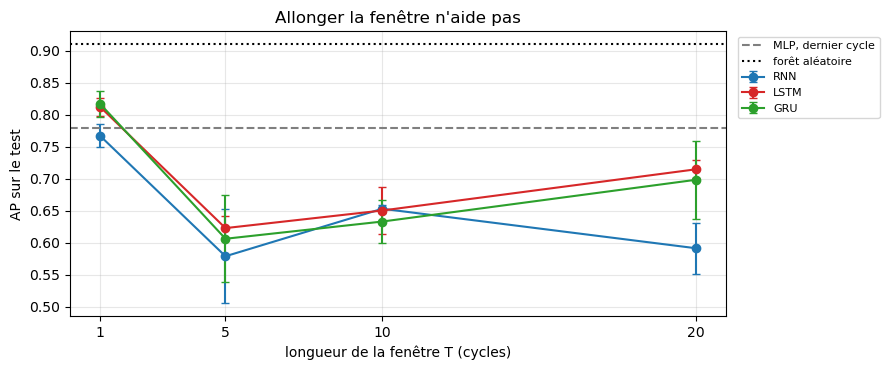

In [16]:
LONGUEURS = (1, 5, 10, 20)
balayage = [dict(modele=r["modele"], T=T_FEN, graine=r["graine"], AP=r["AP"], F1=r["F1"])
            for r in resultats if r["modele"] in ("RNN", "LSTM", "GRU")]
t0 = time.time()
for T in LONGUEURS:
    if T == T_FEN:
        continue                                       # déjà entraînés plus haut
    J = jeux(T)
    for nom in ("RNN", "LSTM", "GRU"):
        for g in GRAINES:
            modele, info = entrainer_detecteur(lambda: FABRIQUES[nom](T), J, g)
            seuil = choisir_seuil(probas(modele, J["val"][0]), y_val_np)
            balayage.append(dict(modele=nom, T=T, graine=g, **mesurer(probas(modele, J["test"][0]), y_test_np, seuil)))
    print(f"T = {T:2d} : fait ({time.time() - t0:.0f} s)")

bal = pd.DataFrame(balayage)
moy = bal.pivot_table(index="T", columns="modele", values="AP", aggfunc="mean")[["RNN", "LSTM", "GRU"]]
ecart = bal.pivot_table(index="T", columns="modele", values="AP", aggfunc="std")[["RNN", "LSTM", "GRU"]]
print("\nAP sur le test, moyenne de 3 graines :")
print(moy.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 3.8))
for nom in ("RNN", "LSTM", "GRU"):
    ax.errorbar(moy.index, moy[nom], yerr=ecart[nom], marker="o", capsize=3, color=COULEURS[nom], label=nom)
ax.axhline(tab.loc["MLP, dernier cycle", "AP"], color="tab:gray", ls="--", label="MLP, dernier cycle")
ax.axhline(res_rf["AP"], color="black", ls=":", label="forêt aléatoire")
ax.set_xticks(LONGUEURS); ax.set_xlabel("longueur de la fenêtre T (cycles)"); ax.set_ylabel("AP sur le test")
ax.set_title("Allonger la fenêtre n'aide pas"); ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

### 7.2 Interpréter (2) : quels pas de temps le réseau regarde-t-il ?

La **saillance** mesure la sensibilité de la sortie à chaque entrée : $\big|\partial z / \partial x_{k,j}\big|$ pour la position $k$ de la fenêtre et la variable $j$, moyennée sur les fenêtres du test, puis divisée par la somme totale. C'est le même calcul de gradient qu'à la séance 4 (le gradient qui remonte le temps), mais sur un réseau **entraîné**. Les variables étant centrées et réduites, leurs saillances sont comparables.

On sépare deux familles, d'après l'autocorrélation mesurée en 4.5 :

- **sans mémoire** : vitesse, couple, puissance et type (autocorrélation nulle). Leurs valeurs aux cycles passés ne disent **rien** de la panne du cycle $t$ ;
- **lentes** : températures, $\Delta T$, usure et contrainte. Leurs valeurs passées sont presque égales à la valeur courante : s'en servir est redondant, mais pas absurde.

Part de la saillance portée par les 9 cycles passés :
  MLP, fenêtre à plat  : toutes variables 80.6%   variables sans mémoire 79.0%   variables lentes 84.6%
  RNN                  : toutes variables 62.4%   variables sans mémoire 56.9%   variables lentes 69.9%
  LSTM                 : toutes variables 64.3%   variables sans mémoire 50.6%   variables lentes 79.0%
  GRU                  : toutes variables 75.7%   variables sans mémoire 72.9%   variables lentes 80.3%


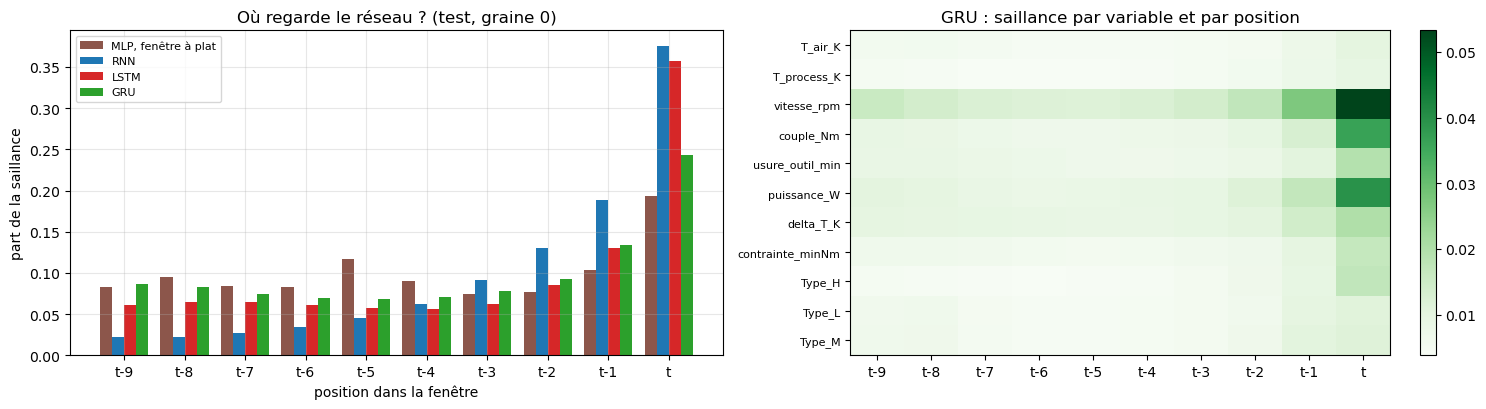

In [17]:
SANS_MEMOIRE = ["vitesse_rpm", "couple_Nm", "puissance_W", "Type_H", "Type_L", "Type_M"]
LENTES = ["T_air_K", "T_process_K", "usure_outil_min", "delta_T_K", "contrainte_minNm"]
i_sans, i_lentes = [ENTREES.index(v) for v in SANS_MEMOIRE], [ENTREES.index(v) for v in LENTES]

def saillance(modele, X):
    # |dz/dx| moyen sur les fenêtres : une valeur par position et par variable, normalisée à une somme de 1
    modele.eval()
    x = X.clone().requires_grad_(True)
    modele(x).sum().backward()
    s = x.grad.abs().mean(dim=0).numpy()       # (T, d)
    return s / s.sum()

positions = np.arange(-T_FEN + 1, 1)
etiquettes = [f"t{k:+d}" if k else "t" for k in positions]
S = {nom: saillance(modeles[(nom, 0)], J10["test"][0]) for nom in ("MLP, fenêtre à plat", "RNN", "LSTM", "GRU")}
print(f"Part de la saillance portée par les {T_FEN - 1} cycles passés :")
for nom, s in S.items():
    part_passe = lambda cols: s[:-1, cols].sum() / s[:, cols].sum()
    print(f"  {nom:20s} : toutes variables {s[:-1].sum():5.1%}   variables sans mémoire {part_passe(i_sans):5.1%}"
          f"   variables lentes {part_passe(i_lentes):5.1%}")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
for k, (nom, s) in enumerate(S.items()):
    ax[0].bar(positions + (k - 1.5) * 0.2, s.sum(axis=1), width=0.2, color=COULEURS[nom], label=nom)
ax[0].set_xticks(positions); ax[0].set_xticklabels(etiquettes)
ax[0].set_xlabel("position dans la fenêtre"); ax[0].set_ylabel("part de la saillance"); ax[0].legend(fontsize=8)
ax[0].set_title("Où regarde le réseau ? (test, graine 0)")
im = ax[1].imshow(S["GRU"].T, aspect="auto", cmap="Greens")
ax[1].set_yticks(range(D)); ax[1].set_yticklabels(ENTREES, fontsize=8)
ax[1].set_xticks(range(T_FEN)); ax[1].set_xticklabels(etiquettes)
ax[1].grid(False); plt.colorbar(im, ax=ax[1], fraction=0.04)
ax[1].set_title("GRU : saillance par variable et par position")
plt.tight_layout(); plt.show()

### 7.3 Interpréter (3) : quelles pannes sont détectées ?

Pour chaque mode, le nombre de pannes du test détectées au seuil choisi (graine 0 pour les réseaux).

In [18]:
test = df[m_test].reset_index(drop=True)
sans_mode = (test.panne == 1) & (test[MODES].sum(axis=1) == 0)
groupes = {m: (test.panne == 1) & (test[m] == 1) for m in MODES}
groupes["sans mode"] = sans_mode
groupes = {k: v.values for k, v in groupes.items() if v.sum() > 0}
lignes = []
for nom, (p, s) in [("Forêt aléatoire", (p_rf, seuil_rf))] + [(n, p_tests[(n, 0)]) for n in FABRIQUES]:
    pred = p > s
    lignes.append({"modèle": nom, **{k: f"{int(pred[v].sum())}/{int(v.sum())}" for k, v in groupes.items()},
                   "fausses alertes": int((pred & (test.panne.values == 0)).sum())})
print("Pannes détectées / pannes du test, par mode (une panne peut avoir plusieurs modes) :")
print(pd.DataFrame(lignes).to_string(index=False))

Pannes détectées / pannes du test, par mode (une panne peut avoir plusieurs modes) :
             modèle TWF HDF   PWF   OSF sans mode  fausses alertes
    Forêt aléatoire 0/4 9/9 15/15 11/11       0/1                1
 MLP, dernier cycle 0/4 9/9 10/15 11/11       0/1               12
MLP, fenêtre à plat 0/4 3/9  5/15  6/11       0/1               28
                RNN 0/4 7/9 11/15  5/11       0/1                9
               LSTM 0/4 6/9  9/15  9/11       0/1               20
                GRU 1/4 6/9 10/15  8/11       0/1               15


### 7.4 Interpréter (4) : quelles variables comptent ?

**Importance par permutation** : on mélange une variable entre les fenêtres du test (la même permutation pour tous les pas de temps), et on mesure la baisse d'AP. Si l'AP ne baisse pas, le modèle n'utilisait pas cette variable. Les trois colonnes du type sont mélangées ensemble. Même calcul pour la forêt aléatoire, sur le dernier cycle.

Baisse d'AP sur le test quand on mélange la variable (moyenne de 5 permutations) :
                  GRU (fenêtre de 10)  forêt aléatoire
couple_Nm                       0.363            0.025
puissance_W                     0.302            0.180
vitesse_rpm                     0.241            0.243
delta_T_K                       0.110            0.210
T_air_K                         0.061           -0.002
usure_outil_min                 0.041            0.026
contrainte_minNm                0.034            0.144
T_process_K                    -0.002            0.002
Type                           -0.010            0.021


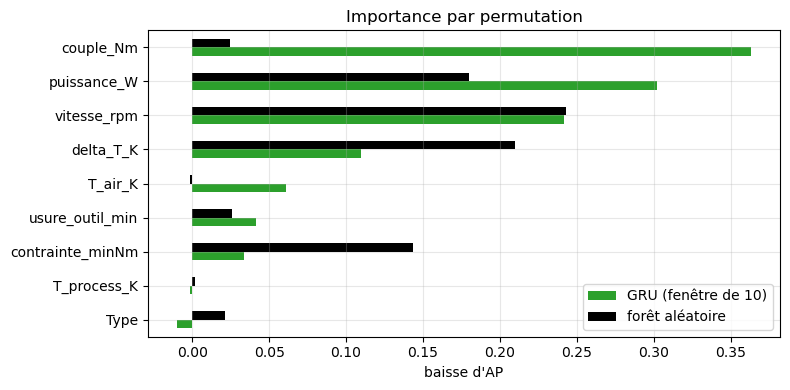

In [19]:
GROUPES_VAR = {v: [ENTREES.index(v)] for v in MESURES + METIER}
GROUPES_VAR["Type"] = [ENTREES.index(c) for c in ("Type_H", "Type_L", "Type_M")]

def importance_permutation(score, X, n_rep=5, graine=0):
    rng_ = np.random.default_rng(graine)
    base, baisses = score(X), {}
    for nom, cols in GROUPES_VAR.items():
        b = []
        for _ in range(n_rep):
            Xp = X.clone() if torch.is_tensor(X) else X.copy()
            perm = rng_.permutation(len(X))
            Xp[..., cols] = X[perm][..., cols]
            b.append(base - score(Xp))
        baisses[nom] = float(np.mean(b))
    return pd.Series(baisses)

imp = pd.DataFrame({
    "GRU (fenêtre de 10)": importance_permutation(lambda X: average_precision_score(y_test_np, probas(modeles[("GRU", 0)], X)), J10["test"][0]),
    "forêt aléatoire": importance_permutation(lambda X: average_precision_score(y_test_np, rf.predict_proba(X)[:, 1]), X_tab[m_test])})
imp = imp.sort_values("GRU (fenêtre de 10)")
print("Baisse d'AP sur le test quand on mélange la variable (moyenne de 5 permutations) :")
print(imp.iloc[::-1].round(3).to_string())
imp.plot.barh(figsize=(8, 4), color=["tab:green", "black"])
plt.xlabel("baisse d'AP"); plt.title("Importance par permutation"); plt.tight_layout(); plt.show()

**Ce qu'il faut retenir de la détection de pannes.**

1. **La mémoire ne sert à rien ici : elle gêne.** Sans passé ($T = 1$), le LSTM et le GRU atteignent une AP de 0,81 à 0,82, au niveau du MLP. Dès $T = 5$, les trois réseaux perdent de 0,1 à 0,2 d'AP.
2. **Pourquoi ?** D'après les règles de la section 4.4, chaque panne est une fonction du **cycle courant** : le passé n'apprend rien sur la panne du cycle $t$. Pour la vitesse, le couple et la puissance, qui n'ont aucune mémoire, les cycles passés sont même du pur bruit. Pourtant, les réseaux entraînés mettent de 51 % (LSTM) à 73 % (GRU) de leur saillance sur les valeurs **passées** de ces variables (section 7.2). Avec 243 pannes d'apprentissage, ils ont trouvé dans ce bruit des coïncidences qui ne se répètent pas sur le test : c'est du **sur-apprentissage**. Une fenêtre plus longue offre plus de bruit à apprendre.
3. **Presque aucune TWF n'est détectée** (une seule, par le GRU) : l'usure de casse est tirée au hasard entre 200 et 240 min, c'est presque une panne aléatoire. La forêt détecte toutes les HDF, PWF et OSF ; les réseaux récurrents en ratent de 2 à 6 dans chacun de ces trois modes.
4. **Les variables des règles dominent** l'importance par permutation : vitesse, puissance et $\Delta T$ pour les deux modèles, plus la contrainte pour la forêt. Le GRU s'appuie beaucoup sur le couple et presque pas sur la contrainte, ce qui est cohérent avec les OSF qu'il manque.
5. **La leçon d'ingénieur : choisissez l'architecture d'après la façon dont les données sont produites.** Ici, un modèle sans mémoire suffit, et le détecteur à règles de l'exercice 2 fait encore mieux (F1 de 0,93 sur le test), sans aucun apprentissage. Une mémoire n'est utile que si une grandeur nécessaire **n'est pas mesurée au cycle courant** et doit être reconstituée à partir du passé. C'est le cas de la section 8.

## 8. Sans capteur d'usure : un réseau récurrent comme capteur virtuel

Beaucoup de machines **ne mesurent pas l'usure** de l'outil. En revanche, l'atelier connaît deux choses : le **type** de chaque produit (ordre de fabrication) et les **changements d'outil** (journal de maintenance). D'après la section 4.5, cela suffit en principe : l'usure est la somme des incréments depuis le dernier changement d'outil. Mais il faut s'en **souvenir** pendant jusqu'à 101 cycles : c'est un vrai travail pour une mémoire.

Le réseau devient un **capteur virtuel** (*soft sensor*) : il estime une grandeur non mesurée à partir des grandeurs mesurées.

- **Une séquence = la vie d'un outil**, du changement d'outil au suivant : 120 séquences de 11 à 101 cycles, complétées par des zéros jusqu'à 101. L'état initial $\mathbf{h}_0 = \mathbf{0}$ : le changement d'outil remet la mémoire à zéro.
- **Entrées** ($d = 7$) : $T_{air}$, $T_{process}$, vitesse, couple et le type en *one-hot*. **Ni l'usure, ni la contrainte.**
- **Sortie** : l'usure estimée **à chaque cycle**, architecture **plusieurs vers plusieurs** (*many-to-many*). Perte : erreur quadratique moyenne, calculée seulement sur les cycles réels (masque). Mesure : la RMSE $= \sqrt{\tfrac{1}{N}\sum_k (\hat{y}_k-y_k)^2}$, en minutes.
- Mêmes partitions par outil qu'en section 7 : 84 outils pour l'apprentissage, 18 pour la validation, 18 pour le test. Adam ($\eta = 10^{-2}$, décroissance cosinus), lots de 8 outils, 150 époques, on garde l'époque à la meilleure RMSE de validation ; 3 graines.

Deux références sans réseau récurrent :

- un **MLP par cycle** : il voit les mêmes entrées, mais un cycle à la fois, sans mémoire ;
- un **compteur de cycles** : usure $\approx a \times$ (nombre de cycles depuis le changement d'outil) $+ b$, avec $a$ et $b$ ajustés sur l'apprentissage. C'est la solution d'un ingénieur qui connaît le procédé.

In [20]:
ENTREES_SV = ["T_air_K", "T_process_K", "vitesse_rpm", "couple_Nm", "Type_H", "Type_L", "Type_M"]
X_sv = pd.get_dummies(df[ENTREES_SV[:4] + ["Type"]], columns=["Type"], dtype=float)[ENTREES_SV].values.astype(np.float32)
X_sv = (X_sv - X_sv[m_app].mean(0)) / X_sv[m_app].std(0)
D_SV, ECHELLE, L_MAX = len(ENTREES_SV), 100.0, int(vie.max())    # usure prédite en centaines de minutes

def sequences_outils(partition):
    outils = sorted(o for o, p in PARTITION.items() if p == partition)
    X = np.zeros((len(outils), L_MAX, D_SV), np.float32)
    Y = np.zeros((len(outils), L_MAX), np.float32)
    M = np.zeros((len(outils), L_MAX), bool)
    for k, o in enumerate(outils):
        lignes_o = np.where(outil == o)[0]
        X[k, :len(lignes_o)], Y[k, :len(lignes_o)], M[k, :len(lignes_o)] = X_sv[lignes_o], usure[lignes_o] / ECHELLE, True
    return torch.tensor(X), torch.tensor(Y), torch.tensor(M), outils

SEQ = {p: sequences_outils(p) for p in ("apprentissage", "validation", "test")}
for p, (X_, Y_, M_, o_) in SEQ.items():
    print(f"{p:13s} : {tuple(X_.shape)} = (outils, cycles, d), {int(M_.sum())} cycles réels")

class CapteurVirtuel(nn.Module):
    def __init__(self, cell, d, h=32):
        super().__init__(); self.rnn = CLASSES[cell](d, h, batch_first=True); self.tete = nn.Linear(h, 1)
    def forward(self, x):                      # x : (outils, cycles, d)
        etats, _ = self.rnn(x)                 # h_0 = 0 au changement d'outil
        return self.tete(etats).squeeze(-1)    # une estimation par cycle

class MLPParCycle(nn.Module):
    def __init__(self, d):
        super().__init__(); self.net = mlp(d)
    def forward(self, x):
        return self.net(x).squeeze(-1)

def rmse_min(modele, partition):
    X, Y, M, _ = SEQ[partition]
    modele.eval()
    with torch.no_grad():
        p = modele(X)
    return float(torch.sqrt(((p - Y)[M] ** 2).mean())) * ECHELLE, (p * ECHELLE).numpy()

def entrainer_capteur(fabrique, graine, lr, epoques=150, taille_lot=8):
    torch.manual_seed(graine)
    modele = fabrique()
    Xa, Ya, Ma, _ = SEQ["apprentissage"]
    opt = torch.optim.Adam(modele.parameters(), lr=lr)
    planif = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epoques)
    gen = torch.Generator().manual_seed(graine)
    meilleur, etat, ep_best, t0 = float("inf"), None, 0, time.time()
    for ep in range(1, epoques + 1):
        modele.train()
        ordre = torch.randperm(len(Xa), generator=gen)
        for i_ in range(0, len(Xa), taille_lot):
            idx = ordre[i_:i_ + taille_lot]
            l = ((modele(Xa[idx]) - Ya[idx])[Ma[idx]] ** 2).mean()
            opt.zero_grad(); l.backward()
            nn.utils.clip_grad_norm_(modele.parameters(), 1.0)
            opt.step()
        planif.step()
        r, _ = rmse_min(modele, "validation")
        if r < meilleur:
            meilleur, ep_best, etat = r, ep, copy.deepcopy(modele.state_dict())
    modele.load_state_dict(etat); modele.eval()
    return modele, dict(rmse_val=meilleur, epoque=ep_best, duree=time.time() - t0)

CAPTEURS = {"MLP par cycle": (lambda: MLPParCycle(D_SV), 3e-3),
            "RNN": (lambda: CapteurVirtuel("rnn", D_SV, H), 1e-2),
            "LSTM": (lambda: CapteurVirtuel("lstm", D_SV, H), 1e-2),
            "GRU": (lambda: CapteurVirtuel("gru", D_SV, H), 1e-2)}
res_sv, capteurs = [], {}
for nom, (fab, lr) in CAPTEURS.items():
    for g in GRAINES:
        modele, info = entrainer_capteur(fab, g, lr)
        rmse_test, _ = rmse_min(modele, "test")
        res_sv.append(dict(modele=nom, graine=g, params=nb_params(modele), rmse_test=rmse_test, **info))
        capteurs[(nom, g)] = modele
    r = pd.DataFrame(res_sv); r = r[r.modele == nom]
    print(f"{nom:14s} : RMSE test {r.rmse_test.mean():6.2f} ± {r.rmse_test.std():5.2f} min   {r.duree.mean():4.1f} s par entraînement")

apprentissage : (84, 101, 7) = (outils, cycles, d), 6977 cycles réels
validation    : (18, 101, 7) = (outils, cycles, d), 1525 cycles réels
test          : (18, 101, 7) = (outils, cycles, d), 1498 cycles réels


MLP par cycle  : RMSE test  64.22 ±  0.11 min    0.8 s par entraînement


RNN            : RMSE test   7.08 ±  2.45 min    3.9 s par entraînement


LSTM           : RMSE test   1.74 ±  0.15 min   10.4 s par entraînement


GRU            : RMSE test   1.31 ±  0.24 min   10.2 s par entraînement


compteur de cycles : usure ≈ 2.588 x cycles + 0.31  ->  RMSE test 6.26 min
écart-type de l'usure sur le test : 63.69 min (RMSE d'une prédiction constante égale à la moyenne)

RMSE de l'usure estimée sur les 18 outils du test (minutes), moyenne ± écart-type sur 3 graines :
                    paramètres RMSE test (min)  durée (s)
modele                                                   
MLP par cycle             2625    64.22 ± 0.11        0.8
RNN                       1345     7.08 ± 2.45        3.9
LSTM                      5281     1.74 ± 0.15       10.4
GRU                       3969     1.31 ± 0.24       10.2
Compteur de cycles           2            6.26        NaN


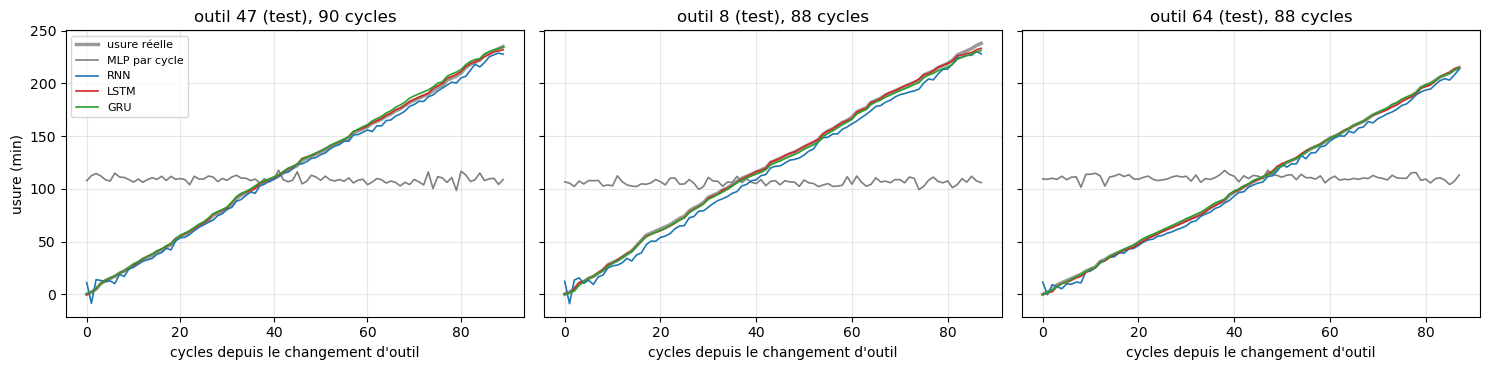

In [21]:
k_cycles = df.groupby("outil").cumcount().values                  # cycles depuis le changement d'outil
a_, b_ = np.polyfit(k_cycles[m_app], usure[m_app], 1)
rmse_compteur = float(np.sqrt(np.mean((a_ * k_cycles[m_test] + b_ - usure[m_test]) ** 2)))
print(f"compteur de cycles : usure ≈ {a_:.3f} x cycles + {b_:.2f}  ->  RMSE test {rmse_compteur:.2f} min")
print(f"écart-type de l'usure sur le test : {usure[m_test].std():.2f} min (RMSE d'une prédiction constante égale à la moyenne)")

rs = pd.DataFrame(res_sv)
tab_sv = rs.groupby("modele", sort=False).agg(params=("params", "first"), rmse=("rmse_test", "mean"),
                                              rmse_std=("rmse_test", "std"), duree=("duree", "mean"))
tab_sv.loc["Compteur de cycles"] = [2, rmse_compteur, np.nan, np.nan]
print("\nRMSE de l'usure estimée sur les 18 outils du test (minutes), moyenne ± écart-type sur 3 graines :")
print(pd.DataFrame({"paramètres": tab_sv.params.astype(int),
                    "RMSE test (min)": [f"{m:.2f}" + ("" if np.isnan(s) else f" ± {s:.2f}") for m, s in zip(tab_sv.rmse, tab_sv.rmse_std)],
                    "durée (s)": tab_sv.duree.round(1)}).to_string())

# meilleure graine de chaque réseau, choisie sur la validation
meilleurs_sv = {}
for nom in CAPTEURS:
    graine_val = int(rs[rs.modele == nom].sort_values("rmse_val").graine.iloc[0])
    meilleurs_sv[nom] = capteurs[(nom, graine_val)]
_, _, M_test, outils_test = SEQ["test"]
longs = np.argsort(-M_test.sum(1).numpy())[:3]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, k in zip(ax, longs):
    n = int(M_test[k].sum())
    a.plot(SEQ["test"][1][k, :n] * ECHELLE, "k", lw=2.5, alpha=0.4, label="usure réelle")
    for nom in ("MLP par cycle", "RNN", "LSTM", "GRU"):
        a.plot(rmse_min(meilleurs_sv[nom], "test")[1][k, :n], lw=1.2,
               color=COULEURS.get(nom, "tab:gray"), label=nom)
    a.set_title(f"outil {outils_test[k]} (test), {n} cycles"); a.set_xlabel("cycles depuis le changement d'outil")
ax[0].set_ylabel("usure (min)"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

L'erreur dépend-elle de la position dans la vie de l'outil ? Plus le cycle est loin du changement d'outil, plus le réseau doit se souvenir longtemps.

In [22]:
X_t, Y_t, M_t, _ = SEQ["test"]
pos = np.broadcast_to(np.arange(L_MAX), M_t.shape)
tranches = [(0, 25), (25, 50), (50, 75), (75, L_MAX)]
lignes = []
for nom in ("RNN", "LSTM", "GRU"):
    err = rmse_min(meilleurs_sv[nom], "test")[1] - Y_t.numpy() * ECHELLE
    ligne = {"modèle": nom}
    for lo, hi in tranches:
        sel = M_t.numpy() & (pos >= lo) & (pos < hi)
        ligne[f"cycles {lo} à {hi - 1}"] = round(float(np.sqrt(np.mean(err[sel] ** 2))), 2)
    lignes.append(ligne)
print("RMSE (min) selon la position dans la vie de l'outil, meilleure graine sur la validation :")
print(pd.DataFrame(lignes).to_string(index=False))

RMSE (min) selon la position dans la vie de l'outil, meilleure graine sur la validation :
modèle  cycles 0 à 24  cycles 25 à 49  cycles 50 à 74  cycles 75 à 100
   RNN           4.35            3.48            4.59             4.93
  LSTM           1.16            1.61            1.84             1.62
   GRU           1.06            1.37            1.47             2.18


### 8.1 Ouvrir le LSTM : la cellule comme accumulateur

On recalcule le LSTM **à la main**, avec les poids appris et les formules de la section 6, sur l'outil le plus long du test. PyTorch empile les blocs dans l'ordre $i, f, g, o$ ; les deux vecteurs de biais s'additionnent. On vérifie qu'on retrouve la sortie de `nn.LSTM`, puis on cherche l'unité dont la mémoire $c_t$ suit le mieux l'usure réelle.

écart maximal entre le calcul à la main et nn.LSTM : 1.5250039586689468e-07
unité 14 : corrélation entre c_t et l'usure réelle = +0.999 (16 unités sur 32 au-delà de 0,9 en valeur absolue)
porte d'oubli f de l'unité 14 : 0.67 en moyenne sur les cycles 1 à 5, 0.94 sur les 10 derniers cycles
porte d'entrée i de l'unité 14 : 0.57 en moyenne ; candidat g : +0.82 en moyenne ; accroissement moyen de c_t par cycle : +0.096


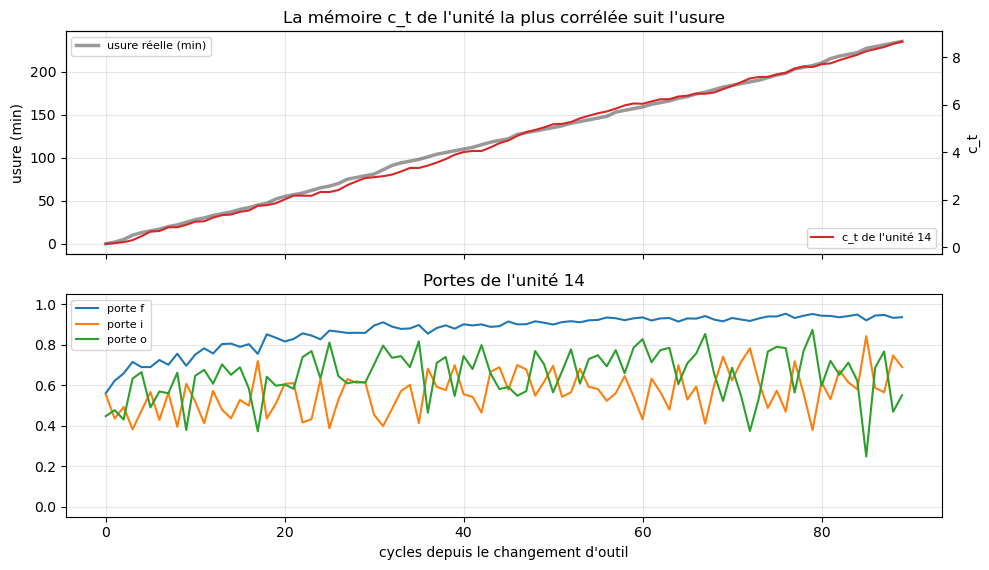

In [23]:
cellule = meilleurs_sv["LSTM"].rnn
Wi, Wh = cellule.weight_ih_l0.detach().numpy(), cellule.weight_hh_l0.detach().numpy()
b_lstm = (cellule.bias_ih_l0 + cellule.bias_hh_l0).detach().numpy()
k = int(longs[0]); n = int(M_t[k].sum())
x_seq = X_t[k, :n].numpy()

h_, c_ = np.zeros(H), np.zeros(H)
traces = {nom: [] for nom in ("i", "f", "g", "o", "c", "h")}
for t in range(n):
    z = Wi @ x_seq[t] + Wh @ h_ + b_lstm
    i_g, f_g, g_g, o_g = sigmoide(z[:H]), sigmoide(z[H:2 * H]), np.tanh(z[2 * H:3 * H]), sigmoide(z[3 * H:])
    c_ = f_g * c_ + i_g * g_g
    h_ = o_g * np.tanh(c_)
    for nom, v in zip(("i", "f", "g", "o", "c", "h"), (i_g, f_g, g_g, o_g, c_, h_)):
        traces[nom].append(v)
traces = {nom: np.array(v) for nom, v in traces.items()}
with torch.no_grad():
    h_torch = cellule(X_t[k:k + 1, :n])[0][0].numpy()
print("écart maximal entre le calcul à la main et nn.LSTM :", float(np.abs(traces["h"] - h_torch).max()))

vraie = Y_t[k, :n].numpy() * ECHELLE
corr_c = np.array([np.corrcoef(traces["c"][:, u], vraie)[0, 1] for u in range(H)])
u = int(np.argmax(np.abs(corr_c)))
print(f"unité {u} : corrélation entre c_t et l'usure réelle = {corr_c[u]:+.3f} "
      f"({int((np.abs(corr_c) > 0.9).sum())} unités sur {H} au-delà de 0,9 en valeur absolue)")
print(f"porte d'oubli f de l'unité {u} : {traces['f'][1:6, u].mean():.2f} en moyenne sur les cycles 1 à 5, "
      f"{traces['f'][-10:, u].mean():.2f} sur les 10 derniers cycles")
print(f"porte d'entrée i de l'unité {u} : {traces['i'][:, u].mean():.2f} en moyenne ; candidat g : {traces['g'][:, u].mean():+.2f} en moyenne ; "
      f"accroissement moyen de c_t par cycle : {np.diff(traces['c'][:, u]).mean():+.3f}")

fig, ax = plt.subplots(2, 1, figsize=(10, 5.8), sharex=True)
ax[0].plot(vraie, "k", lw=2.5, alpha=0.4, label="usure réelle (min)")
ax0b = ax[0].twinx(); ax0b.plot(traces["c"][:, u], color="tab:red", label=f"c_t de l'unité {u}")
ax0b.grid(False); ax[0].set_ylabel("usure (min)"); ax0b.set_ylabel("c_t")
ax[0].legend(loc="upper left", fontsize=8); ax0b.legend(loc="lower right", fontsize=8)
ax[0].set_title("La mémoire c_t de l'unité la plus corrélée suit l'usure")
for nom, coul in (("f", "tab:blue"), ("i", "tab:orange"), ("o", "tab:green")):
    ax[1].plot(traces[nom][:, u], color=coul, label=f"porte {nom}")
ax[1].set_ylim(-0.05, 1.05); ax[1].set_xlabel("cycles depuis le changement d'outil"); ax[1].legend(fontsize=8)
ax[1].set_title(f"Portes de l'unité {u}")
plt.tight_layout(); plt.show()

**À observer.**

- **Sans mémoire, rien à faire** : le MLP par cycle se trompe de 64 min en moyenne, autant qu'une constante égale à la moyenne. Rien dans le cycle courant ne dit où en est l'outil.
- **Le GRU (1,3 min) et le LSTM (1,7 min) reconstituent l'usure** à moins de 1 % de son étendue (0 à 253 min). Ils battent le compteur de cycles (6,3 min) : comme la récurrence exacte de l'exercice 3, ils pondèrent chaque cycle par le type du produit, qu'ils ont appris à lire.
- **Le RNN simple fait 7,1 ± 2,5 min** selon la graine : 4 à 5 fois moins précis en moyenne, et instable. Même sa meilleure graine reste 2 à 4 fois moins précise à toutes les positions de la vie de l'outil. Sa mise à jour $\mathbf{h}_t = \tanh(W_{xh}\mathbf{x}_t + W_{hh}\mathbf{h}_{t-1} + \mathbf{b})$ réécrit tout l'état à chaque pas. Le LSTM ($\mathbf{c}_t = \mathbf{f}_t\odot\mathbf{c}_{t-1} + \mathbf{i}_t\odot\tilde{\mathbf{c}}_t$) et le GRU ($\mathbf{h}_t = (1-\mathbf{z}_t)\odot\mathbf{n}_t + \mathbf{z}_t\odot\mathbf{h}_{t-1}$) ont un chemin **additif** : ils ajoutent un petit incrément sans abîmer ce qui est déjà stocké. C'est l'argument de la séance 4, vérifié ici sur une tâche de comptage.
- **Dans le LSTM**, la mémoire $c_t$ de l'unité 14 suit l'usure avec une corrélation de 0,999, et la moitié des unités dépassent 0,9. Ce n'est pas l'accumulateur exact de l'exercice 3, qui aurait $f = 1$ : la porte d'oubli de cette unité passe de 0,67 en début de vie de l'outil à 0,94 en fin de vie, et la porte d'entrée ajoute à chaque cycle de quoi compenser la fuite. Le réseau a trouvé sa propre façon de compter.

### 8.2 Détecter les pannes sans capteur d'usure

L'usure estimée sert-elle à détecter les pannes ? On reprend la forêt aléatoire (la meilleure en section 7) dans trois situations :

1. **usure mesurée** : les 11 variables de la section 7 ;
2. **sans capteur d'usure** : on retire l'usure et la contrainte ;
3. **usure estimée** par le GRU de la section 8 (meilleure graine sur la validation) : on remplace l'usure par son estimation, et la contrainte par estimation $\times$ couple.

In [24]:
gru_sv = meilleurs_sv["GRU"]
usure_estimee = np.zeros(len(df), np.float32)
for p in ("apprentissage", "validation", "test"):
    _, pred = rmse_min(gru_sv, p)
    for k_, o in enumerate(SEQ[p][3]):
        lignes_o = np.where(outil == o)[0]
        usure_estimee[lignes_o] = pred[k_, :len(lignes_o)]

base = pd.get_dummies(df[["T_air_K", "T_process_K", "vitesse_rpm", "couple_Nm", "puissance_W", "delta_T_K", "Type"]],
                      columns=["Type"], dtype=float)
variantes = {"usure mesurée": X_tab,
             "sans capteur d'usure": base.values,
             "usure estimée par le GRU": base.assign(usure=usure_estimee, contrainte=usure_estimee * df.couple_Nm).values}
lignes = []
for nom, X_ in variantes.items():
    foret = RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced",
                                   random_state=SEED, n_jobs=-1).fit(X_[m_app], y_tab[m_app])
    s = choisir_seuil(foret.predict_proba(X_[m_val])[:, 1], y_val_np)
    p = foret.predict_proba(X_[m_test])[:, 1]
    pred = p > s
    lignes.append({"forêt aléatoire": nom, **{k_: round(v, 3) for k_, v in mesurer(p, y_test_np, s).items()},
                   **{f"{m} détectées": f"{int(pred[groupes[m]].sum())}/{int(groupes[m].sum())}" for m in ("TWF", "OSF")}})
print(f"Test : {int(y_test_np.sum())} pannes. RMSE de l'usure estimée sur le test : "
      f"{np.sqrt(np.mean((usure_estimee[m_test] - usure[m_test]) ** 2)):.2f} min")
print(pd.DataFrame(lignes).to_string(index=False))

Test : 39 pannes. RMSE de l'usure estimée sur le test : 1.42 min
         forêt aléatoire    AP    F1  rappel  precision TWF détectées OSF détectées
           usure mesurée 0.910 0.919   0.872      0.971           0/4         11/11
    sans capteur d'usure 0.729 0.742   0.590      1.000           0/4          1/11
usure estimée par le GRU 0.907 0.917   0.846      1.000           0/4         11/11


**À observer.**

- **Sans capteur d'usure**, la forêt ne détecte plus qu'**une OSF sur 11** : l'AP tombe de 0,91 à 0,73.
- **Avec l'usure estimée par le GRU**, elle retrouve les 11 OSF et pratiquement ses scores d'origine (AP de 0,907 contre 0,910, F1 de 0,917 contre 0,919). Le réseau récurrent **remplace un capteur**.
- Les TWF restent invisibles dans les trois cas, pour la raison vue en section 7.
- C'est le bon usage de la mémoire sur ce jeu : le réseau récurrent reconstitue l'état caché du procédé (l'usure), puis un modèle sans mémoire décide, cycle par cycle.

## 9. Et sur cible embarquée ?

Sur le STM32F446, on compare les modèles du lab : taille en int8, part de la Flash, calcul et mémoire. En **flux** (*streaming*), un réseau récurrent n'a pas besoin de relire la fenêtre : à chaque nouveau cycle, il fait **un seul pas** à partir de l'état gardé en SRAM. Le MLP à plat, lui, recalcule toute la fenêtre et doit la garder en mémoire. Latence : 2 à 4 cycles d'horloge par MAC, à 180 MHz (estimation, à mesurer sur cible).

In [25]:
def mac_mlp(n_entrees, cachees=(64, 32)):
    tailles = [n_entrees, *cachees, 1]
    return sum(a * b for a, b in zip(tailles[:-1], tailles[1:]))

chemin_rf = os.path.join(DOSSIER, "foret.joblib"); joblib.dump(rf, chemin_rf)
noeuds = sum(e.tree_.node_count for e in rf.estimators_)
lignes = [
    ("MLP, dernier cycle (sect. 7)", params_mlp(D), mac_mlp(D), 0),
    (f"MLP, fenêtre à plat de {T_FEN} cycles (sect. 7)", params_mlp(D * T_FEN), mac_mlp(D * T_FEN), 4 * D * T_FEN),
    ("RNN détecteur, d = 11, h = 32 (sect. 7)", FORMULES["RNN"](T_FEN), 1 * H * (D + H) + H, 4 * H),
    ("GRU détecteur, d = 11, h = 32 (sect. 7)", FORMULES["GRU"](T_FEN), 3 * H * (D + H) + H, 4 * H),
    ("LSTM détecteur, d = 11, h = 32 (sect. 7)", FORMULES["LSTM"](T_FEN), 4 * H * (D + H) + H, 8 * H),
    ("GRU capteur virtuel, d = 7, h = 32 (sect. 8)", 3 * H * (D_SV + H + 2) + H + 1, 3 * H * (D_SV + H) + H, 4 * H),
    ("LSTM capteur virtuel, d = 7, h = 32 (sect. 8)", 4 * H * (D_SV + H + 2) + H + 1, 4 * H * (D_SV + H) + H, 8 * H)]
print(f"{'modèle':44s}{'paramètres':>11s}{'int8':>9s}{'% Flash':>9s}{'MAC/cycle':>11s}{'latence':>16s}{'état':>12s}")
for nom, n_p, mac, etat in lignes:
    print(f"{nom:44s}{n_p:11d}{n_p / 1000:7.1f} ko{n_p / FLASH:9.1%}{mac:11d}"
          f"{mac * 2 / FREQ * 1e6:7.0f} à{mac * 4 / FREQ * 1e6:4.0f} µs{etat:8d} oct.")
print(f"\nForêt aléatoire : {len(rf.estimators_)} arbres, {noeuds} nœuds, {os.path.getsize(chemin_rf) / 1e6:.1f} Mo sur disque "
      f"({os.path.getsize(chemin_rf) / FLASH:.0f} fois la Flash)")

modèle                                       paramètres     int8  % Flash  MAC/cycle         latence        état
MLP, dernier cycle (sect. 7)                       2881    2.9 ko     0.5%       2784     31 à  62 µs       0 oct.
MLP, fenêtre à plat de 10 cycles (sect. 7)         9217    9.2 ko     1.8%       9120    101 à 203 µs     440 oct.
RNN détecteur, d = 11, h = 32 (sect. 7)            1473    1.5 ko     0.3%       1408     16 à  31 µs     128 oct.
GRU détecteur, d = 11, h = 32 (sect. 7)            4353    4.4 ko     0.8%       4160     46 à  92 µs     128 oct.
LSTM détecteur, d = 11, h = 32 (sect. 7)           5793    5.8 ko     1.1%       5536     62 à 123 µs     256 oct.
GRU capteur virtuel, d = 7, h = 32 (sect. 8)       3969    4.0 ko     0.8%       3776     42 à  84 µs     128 oct.
LSTM capteur virtuel, d = 7, h = 32 (sect. 8)       5281    5.3 ko     1.0%       5024     56 à 112 µs     256 oct.

Forêt aléatoire : 200 arbres, 42052 nœuds, 3.4 Mo sur disque (7 fois la Flash)


**À retenir.**

- Tous les réseaux du lab tiennent dans **moins de 2 % de la Flash** en int8, et un nouveau cycle coûte **de 16 à 200 µs** environ. Dans AI4I, chaque produit use l'outil de 2 à 5 minutes : un cycle dure des minutes, la marge est énorme.
- L'**état** d'un GRU de 32 unités tient en 128 octets, celui d'un LSTM en 256 octets. C'est tout ce qu'il faut garder entre deux cycles, quelle que soit la durée de la vie de l'outil.
- La forêt aléatoire, la meilleure en section 7, pèse plusieurs mégaoctets sous cette forme : il faudrait l'élaguer fortement (moins d'arbres, moins profonds) et la compiler en C pour l'embarquer.

## 10. Exercices de validation

Chaque fonction ci-dessous renvoie `None` : le vérificateur affiche alors **« À compléter »**. Complétez-les, puis relancez `verifier_tout()`. Le corrigé est à la fin du notebook : essayez d'abord !

In [26]:
def verifier(nom, valeur, attendu, tol=1e-3):
    if valeur is None:
        print(f"{nom} : À compléter")
        return
    try:
        ok = np.allclose(np.asarray(valeur, dtype=float), np.asarray(attendu, dtype=float), atol=tol)
    except Exception:
        ok = False
    if ok:
        print(f"{nom} : Correct")
    else:
        print(f"{nom} : Incorrect (obtenu {np.round(np.asarray(valeur, dtype=float), 4)}, attendu {attendu})")

def verifier_tout():
    verifier("Exercice 1 — paramètres du GRU détecteur (d = 11, h = 32)", params_detecteur("gru", 11, 32), 4353, tol=0)
    verifier("Exercice 1 bis — paramètres du LSTM capteur virtuel (d = 7, h = 32)", params_detecteur("lstm", 7, 32), 5281, tol=0)
    r = detecteur_regles(df)
    verifier("Exercice 2 — détecteur à règles (HDF, PWF, OSF)", None if r is None else np.asarray(r, dtype=int),
             ((df.HDF + df.PWF + df.OSF) > 0).astype(int).values, tol=0)
    verifier("Exercice 3 — usure reconstruite (exemple)", usure_reconstruite(["M", "L", "L", "L", "M", "H"]), [0, 3, 5, 7, 9, 12], tol=0)
    premier = df[df.outil == 0]
    verifier("Exercice 3 bis — usure du premier outil d'AI4I", usure_reconstruite(list(premier.Type)),
             premier.usure_outil_min.values, tol=0)
    r = metriques(30, 10, 9)
    verifier("Exercice 4 — précision, rappel, F1", None if r is None else list(r), [0.75, 0.7692, 0.7595])
    r = cout_mac("gru", 11, 32, 10)
    verifier("Exercice 5 — MAC d'un GRU 11 -> 32 : fenêtre de 10 cycles, puis flux", None if r is None else list(r), [41280, 4128], tol=0)

**Exercice 1 — Compter les paramètres d'un détecteur.** Complétez `params_detecteur(cell, d, h)` : le nombre total de paramètres d'une cellule `"rnn"`, `"gru"` ou `"lstm"` (convention PyTorch) **suivie de la tête linéaire** $h \to 1$. Puis, en dehors du vérificateur : combien de paramètres pour un GRU à **deux couches** empilées de 32 unités ? (La deuxième couche reçoit $d = 32$.)

In [27]:
def params_detecteur(cell, d, h):
    # À compléter
    return None

**Exercice 2 — Le détecteur à règles.** Complétez `detecteur_regles(d)` : elle renvoie un vecteur de 0 et de 1, égal à 1 quand **au moins une** des règles HDF, PWF ou OSF du tableau 3.6 est vraie. Utilisez les colonnes `delta_T_K`, `vitesse_rpm`, `puissance_W`, `contrainte_minNm` et `Type`. Puis, en dehors du vérificateur : calculez son F1 sur le test (`m_test`) et comparez-le aux modèles de la section 7. Quelles pannes ce détecteur ne peut-il pas voir ?

In [28]:
def detecteur_regles(d):
    # À compléter
    return None

**Exercice 3 — La récurrence de l'usure, à la main.** Complétez `usure_reconstruite(types)` : `types` est la liste des types de produits usinés depuis un changement d'outil ; elle renvoie la liste des usures, avec $u_0 = 0$ et $u_t = u_{t-1} + \text{incrément}(\text{type}_{t-1})$ (L : 2 min, M : 3 min, H : 5 min). C'est le « réseau récurrent » exact que les modèles de la section 8 doivent apprendre. Combien de paramètres a-t-il ?

In [29]:
def usure_reconstruite(types):
    # À compléter
    return None

**Exercice 4 — Précision, rappel, F1.** Complétez `metriques(tp, fp, fn)`, qui renvoie le tuple `(precision, rappel, f1)`. Vérification : 30 pannes détectées, 10 fausses alertes, 9 pannes manquées.

In [30]:
def metriques(tp, fp, fn):
    # À compléter
    return None

**Exercice 5 — Fenêtre ou flux ?** Complétez `cout_mac(cell, d, h, T)`, qui renvoie le couple `(mac_fenetre, mac_flux)` : le nombre de MAC de la cellule récurrente pour relire une fenêtre de $T$ pas, puis pour avancer d'un seul pas en flux (on ignore la tête et les non-linéarités). Puis, en dehors du vérificateur : la latence de chacun sur le STM32F446 à 180 MHz et 3 cycles par MAC.

In [31]:
def cout_mac(cell, d, h, T):
    # À compléter
    return None

In [32]:
verifier_tout()

Exercice 1 — paramètres du GRU détecteur (d = 11, h = 32) : À compléter
Exercice 1 bis — paramètres du LSTM capteur virtuel (d = 7, h = 32) : À compléter
Exercice 2 — détecteur à règles (HDF, PWF, OSF) : À compléter
Exercice 3 — usure reconstruite (exemple) : À compléter
Exercice 3 bis — usure du premier outil d'AI4I : À compléter
Exercice 4 — précision, rappel, F1 : À compléter
Exercice 5 — MAC d'un GRU 11 -> 32 : fenêtre de 10 cycles, puis flux : À compléter


## Corrigé

Essayez d'abord les exercices ! Cette section définit les solutions, puis relance le vérificateur.

In [33]:
def params_detecteur(cell, d, h):
    return FACTEUR[cell] * h * (d + h + 2) + h + 1

def detecteur_regles(d):
    seuil_osf = d.Type.map({"L": 11000, "M": 12000, "H": 13000})
    hdf = (d.delta_T_K < 8.6) & (d.vitesse_rpm < 1380)
    pwf = (d.puissance_W < 3500) | (d.puissance_W > 9000)
    osf = d.contrainte_minNm > seuil_osf
    return (hdf | pwf | osf).astype(int).values

def usure_reconstruite(types):
    u = [0]
    for type_precedent in types[:-1]:
        u.append(u[-1] + INCREMENT[type_precedent])
    return u

def metriques(tp, fp, fn):
    p, r = tp / (tp + fp), tp / (tp + fn)
    return p, r, 2 * p * r / (p + r)

def cout_mac(cell, d, h, T):
    pas = FACTEUR[cell] * h * (d + h)
    return T * pas, pas

verifier_tout()

print("\nCompléments :")
gru2 = nn.GRU(D, 32, num_layers=2, batch_first=True)
print(f"  GRU à deux couches de 32 unités + tête : {nb_params(gru2) + 33} paramètres "
      f"(= {3 * 32 * (D + 32 + 2)} + {3 * 32 * (32 + 32 + 2)} + 33)")
pred_regles = detecteur_regles(df)[m_test]
print(f"  détecteur à règles sur le test : F1 = {f1_score(y_test_np, pred_regles):.3f}, "
      f"précision = {precision_score(y_test_np, pred_regles):.3f}, rappel = {recall_score(y_test_np, pred_regles):.3f} "
      "(il ne voit ni TWF, ni RNF, ni les pannes sans mode)")
print("  la récurrence de l'usure n'a aucun paramètre appris : trois incréments (2, 3, 5) et une remise à zéro")
mf, ms = cout_mac("gru", 11, 32, 10)
print(f"  latence à 3 cycles par MAC : fenêtre {mf * 3 / FREQ * 1e6:.0f} µs, flux {ms * 3 / FREQ * 1e6:.0f} µs")

Exercice 1 — paramètres du GRU détecteur (d = 11, h = 32) : Correct
Exercice 1 bis — paramètres du LSTM capteur virtuel (d = 7, h = 32) : Correct
Exercice 2 — détecteur à règles (HDF, PWF, OSF) : Correct
Exercice 3 — usure reconstruite (exemple) : Correct
Exercice 3 bis — usure du premier outil d'AI4I : Correct
Exercice 4 — précision, rappel, F1 : Correct
Exercice 5 — MAC d'un GRU 11 -> 32 : fenêtre de 10 cycles, puis flux : Correct

Compléments :
  GRU à deux couches de 32 unités + tête : 10689 paramètres (= 4320 + 6336 + 33)
  détecteur à règles sur le test : F1 = 0.932, précision = 1.000, rappel = 0.872 (il ne voit ni TWF, ni RNF, ni les pannes sans mode)
  la récurrence de l'usure n'a aucun paramètre appris : trois incréments (2, 3, 5) et une remise à zéro
  latence à 3 cycles par MAC : fenêtre 688 µs, flux 69 µs


## Pour aller plus loin

- **Anticiper au lieu de détecter** : décalez la cible pour prédire la panne du cycle $t+5$ à partir de la fenêtre qui finit en $t$. Quels modes de panne restent prévisibles ? (Pensez à l'autocorrélation de chaque variable, en 4.5.)
- Ajoutez `bidirectional=True` au GRU détecteur. Pourquoi ce réglage est-il **interdit** pour un détecteur en ligne ?
- Capteur virtuel : retirez le type de produit des entrées. Que devient la RMSE ? Pourquoi ?
- Bruitez les températures (bruit gaussien d'écart-type 0,5 K) avant l'entraînement : un réseau récurrent sur une fenêtre de 20 cycles détecte-t-il mieux les HDF qu'un MLP sur le dernier cycle ? Le réseau joue alors le rôle d'un **filtre**.
- Reprenez le découpage chronologique de la section 4.6 et observez ce que devient l'évaluation.
- Quantifiez le GRU en int8 avec ONNX Runtime, comme au lab 3, et mesurez l'écart sur l'AP.

## Références

- Matzka (2020), *Explainable Artificial Intelligence for Predictive Maintenance Applications*, AI4I ; jeu *AI4I 2020 Predictive Maintenance Dataset*, UCI Machine Learning Repository, CC BY 4.0.
- Elman (1990), *Finding structure in time* ; Hochreiter et Schmidhuber (1997), *Long short-term memory* ; Gers, Schmidhuber et Cummins (2000), porte d'oubli ; Cho et al. (2014), GRU.
- Pascanu, Mikolov et Bengio (2013), *On the difficulty of training recurrent neural networks*.
- Saito et Rehmsmeier (2015), *The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets*, PLoS ONE.
- Grinsztajn, Oyallon et Varoquaux (2022), *Why do tree-based models still outperform deep learning on tabular data?*, NeurIPS.
- Kadlec, Gabrys et Strandt (2009), *Data-driven soft sensors in the process industry*, Computers & Chemical Engineering.

In [34]:
print(f"Durée d'exécution du notebook : {time.time() - T0:.0f} s")

Durée d'exécution du notebook : 306 s
